In [ ]:
# ============================================================
# STEP 1: ENVIRONMENT SETUP AND PROJECT INITIALIZATION
# Project: LatentForge
# ============================================================

# Step 1.1: Import the required libraries
import os
import random
import json
import copy
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

# Step 1.2: Connect Google Drive
# This allows us to preserve checkpoints and results across
# Colab runtime disconnections.
from google.colab import drive

drive.mount("/content/drive")

# Step 1.3: Create the permanent project directories
PROJECT_DIR = "/content/drive/MyDrive/LatentForge"

DATA_DIR = os.path.join(PROJECT_DIR, "data")
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
FIGURES_DIR = os.path.join(PROJECT_DIR, "figures")

# Create each directory if it does not already exist
for folder in [DATA_DIR, CHECKPOINT_DIR, RESULTS_DIR, FIGURES_DIR]:
    os.makedirs(folder, exist_ok=True)

# Step 1.4: Select the available computing device
# Use the GPU when available; otherwise, use the CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Step 1.5: Display environment information
print("=" * 55)
print("LATENTFORGE: ENVIRONMENT INITIALIZED")
print("=" * 55)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

print("\nProject directory:", PROJECT_DIR)
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Results directory:", RESULTS_DIR)
print("Figures directory:", FIGURES_DIR)

print("\nStep 1 completed successfully.")

Mounted at /content/drive
LATENTFORGE: ENVIRONMENT INITIALIZED
PyTorch version: 2.11.0+cu130
CUDA available: True
Selected device: cuda
GPU name: Tesla T4

Project directory: /content/drive/MyDrive/LatentForge
Checkpoint directory: /content/drive/MyDrive/LatentForge/checkpoints
Results directory: /content/drive/MyDrive/LatentForge/results
Figures directory: /content/drive/MyDrive/LatentForge/figures

Step 1 completed successfully.


In [ ]:
# ============================================================
# STEP 2: REPRODUCIBILITY AND EXPERIMENT CONFIGURATION
# ============================================================

# Step 2.1: Define the random seed
# Using the same seed helps make experiments more reproducible.
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Step 2.2: Configure the VAE architecture
LATENT_DIM = 16

# Step 2.3: Configure training
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
EPOCHS = 30

# Step 2.4: Define the baseline beta value
# The baseline VAE uses equal weighting: beta = 1.
BASELINE_BETA = 1.0

# Step 2.5: Define the fixed-beta experiments
FIXED_BETA_VALUES = [0.5, 2.0, 4.0]

# Step 2.6: Define the KL warm-up duration
# Beta will gradually increase from 0 to 1 over these epochs.
WARMUP_EPOCHS = 10

# Step 2.7: Display the configuration
print("=" * 55)
print("LATENTFORGE: EXPERIMENT CONFIGURATION")
print("=" * 55)

print("Random seed:", SEED)
print("Latent dimension:", LATENT_DIM)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Maximum epochs per experiment:", EPOCHS)
print("Baseline beta:", BASELINE_BETA)
print("Fixed-beta values:", FIXED_BETA_VALUES)
print("KL warm-up duration:", WARMUP_EPOCHS, "epochs")

print("\nStep 2 completed successfully.")

LATENTFORGE: EXPERIMENT CONFIGURATION
Random seed: 42
Latent dimension: 16
Batch size: 128
Learning rate: 0.001
Maximum epochs per experiment: 30
Baseline beta: 1.0
Fixed-beta values: [0.5, 2.0, 4.0]
KL warm-up duration: 10 epochs

Step 2 completed successfully.


In [ ]:
# ============================================================
# STEP 3: LOAD AND SPLIT THE FASHION-MNIST DATASET
# ============================================================

# Step 3.1: Convert images into PyTorch tensors.
# Pixel values are scaled to the range [0, 1].
transform = transforms.ToTensor()

# Step 3.2: Download or load the official training dataset.
train_dataset = datasets.FashionMNIST(
    root=DATA_DIR,
    train=True,
    download=True,
    transform=transform
)

# Step 3.3: Download or load the official test dataset.
# Keep this dataset separate for final evaluation.
test_dataset = datasets.FashionMNIST(
    root=DATA_DIR,
    train=False,
    download=True,
    transform=transform
)

# Step 3.4: Split the 60,000 training images.
# A fixed generator seed makes the split reproducible.
train_data, val_data = random_split(
    train_dataset,
    [54000, 6000],
    generator=torch.Generator().manual_seed(SEED)
)

# Step 3.5: Create a controlled generator for training shuffling.
train_generator = torch.Generator().manual_seed(SEED)

# Step 3.6: Create the DataLoaders.
# Training data is shuffled; validation and test data are not.
train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=train_generator,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# Step 3.7: Display dataset statistics.
print("=" * 55)
print("LATENTFORGE: DATASET VERIFICATION")
print("=" * 55)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Official test images:", len(test_dataset))

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

# Step 3.8: Verify the image shape and pixel range.
sample_images, sample_labels = next(iter(train_loader))

print("\nBatch image shape:", sample_images.shape)
print("Batch label shape:", sample_labels.shape)
print("Minimum pixel value:", sample_images.min().item())
print("Maximum pixel value:", sample_images.max().item())

# Step 3.9: Check that images have the expected dimensions.
assert sample_images.shape[1:] == (1, 28, 28)
assert len(train_data) == 54000
assert len(val_data) == 6000
assert len(test_dataset) == 10000

print("\nAll dataset checks passed.")
print("Step 3 completed successfully.")

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 289kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.84MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 14.7MB/s]

LATENTFORGE: DATASET VERIFICATION
Training images: 54000
Validation images: 6000
Official test images: 10000
Training batches: 422
Validation batches: 47
Test batches: 79



Batch image shape: torch.Size([128, 1, 28, 28])
Batch label shape: torch.Size([128])
Minimum pixel value: 0.0
Maximum pixel value: 1.0

All dataset checks passed.
Step 3 completed successfully.


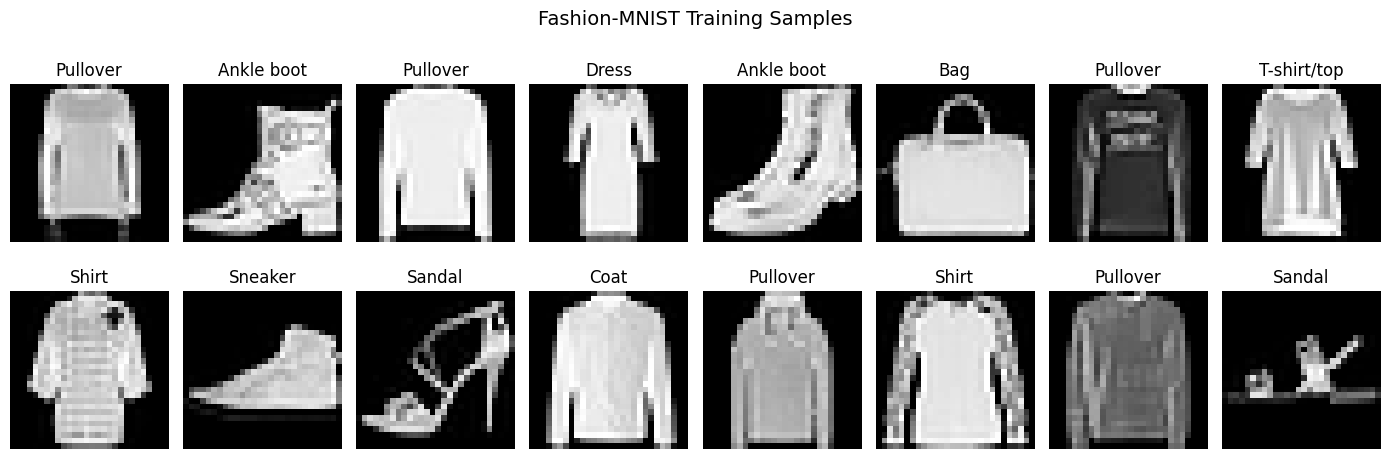

Visualization saved to: /content/drive/MyDrive/LatentForge/figures/fashion_mnist_samples.png
Step 4 completed successfully.


In [ ]:
# ============================================================
# STEP 4: VISUALIZE FASHION-MNIST SAMPLES
# ============================================================

# Step 4.1: Define the names of the 10 Fashion-MNIST classes.
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

# Step 4.2: Get one batch of images from the training dataset.
images, labels = next(iter(train_loader))

# Step 4.3: Create a grid to display the first 16 images.
fig, axes = plt.subplots(2, 8, figsize=(14, 5))

for i, ax in enumerate(axes.flat):
    # Convert the image tensor into a 2D array for visualization.
    image = images[i].squeeze().numpy()

    # Display the grayscale image and its class label.
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(class_names[labels[i].item()])
    ax.axis("off")

plt.suptitle("Fashion-MNIST Training Samples", fontsize=14)
plt.tight_layout()

# Step 4.4: Save the visualization to Google Drive.
figure_path = os.path.join(FIGURES_DIR, "fashion_mnist_samples.png")
plt.savefig(figure_path, dpi=150, bbox_inches="tight")

plt.show()

print("Visualization saved to:", figure_path)
print("Step 4 completed successfully.")

In [ ]:
# ============================================================
# STEP 5: DEFINE THE CONVOLUTIONAL VARIATIONAL AUTOENCODER
# ============================================================

# Step 5.1: Define the VAE model class.
class VAE(nn.Module):

    def __init__(self, latent_dim=16):
        # Initialize the parent PyTorch module.
        super().__init__()

        # Store the dimensionality of the latent space.
        self.latent_dim = latent_dim

        # ----------------------------------------------------
        # Step 5.2: Build the encoder.
        # Input:  (batch_size, 1, 28, 28)
        # Output: (batch_size, 256)
        # ----------------------------------------------------
        self.encoder = nn.Sequential(
            # Reduce spatial dimensions from 28x28 to 14x14.
            nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),

            # Reduce spatial dimensions from 14x14 to 7x7.
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),

            # Flatten the 64 feature maps of size 7x7.
            nn.Flatten(),

            # Learn a compact hidden representation.
            nn.Linear(64 * 7 * 7, 256),
            nn.ReLU()
        )

        # Step 5.3: Predict the latent distribution parameters.
        # mu represents the mean of the latent Gaussian.
        self.fc_mu = nn.Linear(256, latent_dim)

        # logvar represents the logarithm of the latent variance.
        self.fc_logvar = nn.Linear(256, latent_dim)

        # ----------------------------------------------------
        # Step 5.4: Build the decoder's fully connected layers.
        # Convert a latent vector into 64 feature maps of size 7x7.
        # ----------------------------------------------------
        self.decoder_input = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),

            nn.Linear(256, 64 * 7 * 7),
            nn.ReLU()
        )

        # ----------------------------------------------------
        # Step 5.5: Build the convolutional decoder.
        # Output: (batch_size, 1, 28, 28)
        # ----------------------------------------------------
        self.decoder = nn.Sequential(
            # Restore the feature-map dimensions.
            nn.Unflatten(1, (64, 7, 7)),

            # Upsample from 7x7 to 14x14.
            nn.ConvTranspose2d(
                64, 32,
                kernel_size=3,
                stride=2,
                padding=1,
                output_padding=1
            ),
            nn.ReLU(),

            # Upsample from 14x14 to 28x28.
            nn.ConvTranspose2d(
                32, 1,
                kernel_size=3,
                stride=2,
                padding=1,
                output_padding=1
            ),

            # Restrict output pixel values to the range [0, 1].
            nn.Sigmoid()
        )

    # Step 5.6: Encode an image into mean and log-variance.
    def encode(self, x):
        features = self.encoder(x)
        mu = self.fc_mu(features)
        logvar = self.fc_logvar(features)

        return mu, logvar

    # Step 5.7: Sample a latent vector using the reparameterization trick.
    def reparameterize(self, mu, logvar):
        # Convert log-variance into standard deviation.
        std = torch.exp(0.5 * logvar)

        # Generate random noise with the same shape as std.
        epsilon = torch.randn_like(std)

        # Construct a differentiable latent sample.
        z = mu + epsilon * std

        return z

    # Step 5.8: Decode a latent vector into an image.
    def decode(self, z):
        features = self.decoder_input(z)
        reconstruction = self.decoder(features)

        return reconstruction

    # Step 5.9: Define the complete forward pass.
    def forward(self, x):
        # Encode the input image.
        mu, logvar = self.encode(x)

        # Sample a latent representation.
        z = self.reparameterize(mu, logvar)

        # Reconstruct the image.
        reconstruction = self.decode(z)

        return reconstruction, mu, logvar


# ============================================================
# STEP 5.10: INITIALIZE THE MODEL
# ============================================================

# Create a fresh model using the configured latent dimension.
model = VAE(latent_dim=LATENT_DIM).to(device)

print("VAE model initialized successfully.")
print("Latent dimension:", model.latent_dim)
print("Device:", device)

VAE model initialized successfully.
Latent dimension: 16
Device: cuda


In [ ]:
# ============================================================
# STEP 5.11: VERIFY THE VAE ARCHITECTURE
# ============================================================

# Step 5.11.1: Obtain one batch of training images.
images, _ = next(iter(train_loader))

# Move the images to the selected device.
images = images.to(device)

# Step 5.11.2: Run the model without calculating gradients.
with torch.no_grad():
    reconstruction, mu, logvar = model(images)

# Step 5.11.3: Display the tensor shapes.
print("Input image shape:       ", images.shape)
print("Reconstructed shape:     ", reconstruction.shape)
print("Latent mean shape:       ", mu.shape)
print("Latent log-variance shape:", logvar.shape)

# Step 5.11.4: Verify the expected shapes.
assert reconstruction.shape == images.shape
assert mu.shape == (images.size(0), LATENT_DIM)
assert logvar.shape == (images.size(0), LATENT_DIM)

# Step 5.11.5: Verify the output pixel range.
assert reconstruction.min().item() >= 0.0
assert reconstruction.max().item() <= 1.0

print("\nAll VAE architecture checks passed.")
print("Step 5 completed successfully.")

Input image shape:        torch.Size([128, 1, 28, 28])
Reconstructed shape:      torch.Size([128, 1, 28, 28])
Latent mean shape:        torch.Size([128, 16])
Latent log-variance shape: torch.Size([128, 16])

All VAE architecture checks passed.
Step 5 completed successfully.


In [ ]:
# ============================================================
# STEP 6: DEFINE THE VAE LOSS FUNCTION
# ============================================================

def vae_loss(reconstructions, images, mu, logvar, beta=1.0):

    # Step 6.1.1: Calculate reconstruction loss.
    # Sum the BCE error across all pixels in each image,
    # then average across the batch.
    reconstruction_loss = F.binary_cross_entropy(
        reconstructions,
        images,
        reduction="sum"
    ) / images.size(0)

    # Step 6.1.2: Calculate KL-divergence loss.
    # Measure how far each learned latent distribution
    # deviates from a standard normal distribution.
    kl_per_image = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp(),
        dim=1
    )

    # Average the KL loss across the batch.
    kl_loss = kl_per_image.mean()

    # Step 6.1.3: Combine reconstruction and KL losses.
    # Beta determines the weight assigned to regularization.
    total_loss = reconstruction_loss + beta * kl_loss

    # Step 6.1.4: Return all three values separately.
    return total_loss, reconstruction_loss, kl_loss


print("VAE loss function defined successfully.")
print("Step 6.1 completed successfully.")

VAE loss function defined successfully.
Step 6.1 completed successfully.


In [ ]:
# ============================================================
# STEP 6.2: VERIFY THE VAE LOSS FUNCTION
# ============================================================

# Step 6.2.1: Obtain a batch of training images.
images, _ = next(iter(train_loader))
images = images.to(device)

# Step 6.2.2: Run a forward pass through the VAE.
model.eval()

with torch.no_grad():
    reconstructions, mu, logvar = model(images)

    # Step 6.2.3: Calculate the loss using the baseline beta.
    total_loss, reconstruction_loss, kl_loss = vae_loss(
        reconstructions,
        images,
        mu,
        logvar,
        beta=BASELINE_BETA
    )

# Step 6.2.4: Display the calculated losses.
print("Total loss:", total_loss.item())
print("Reconstruction loss:", reconstruction_loss.item())
print("KL-divergence loss:", kl_loss.item())

# Step 6.2.5: Verify that the losses are valid.
assert torch.isfinite(total_loss).item()
assert torch.isfinite(reconstruction_loss).item()
assert torch.isfinite(kl_loss).item()

# KL divergence should be non-negative, apart from tiny
# floating-point errors.
assert kl_loss.item() >= -1e-5

# Verify that the total loss follows the defined objective.
expected_loss = reconstruction_loss + BASELINE_BETA * kl_loss

assert torch.allclose(total_loss, expected_loss)

print("\nAll loss-function checks passed.")
print("Step 6 completed successfully.")

Total loss: 613.42626953125
Reconstruction loss: 613.4036865234375
KL-divergence loss: 0.02258942276239395

All loss-function checks passed.
Step 6 completed successfully.


In [ ]:
# ============================================================
# STEP 7.1: DEFINE THE TRAINING FUNCTION
# ============================================================

def train_one_epoch(model, train_loader, optimizer, beta, device):

    # Step 7.1.1: Enable training mode.
    model.train()

    # Step 7.1.2: Initialize accumulators for epoch metrics.
    total_loss_sum = 0.0
    reconstruction_sum = 0.0
    kl_sum = 0.0
    total_images = 0

    # Step 7.1.3: Process each batch of training images.
    for images, _ in train_loader:

        # Move images to the selected device.
        images = images.to(device, non_blocking=True)

        # Clear gradients from the previous batch.
        optimizer.zero_grad(set_to_none=True)

        # Forward pass: reconstruct images and obtain latent parameters.
        reconstructions, mu, logvar = model(images)

        # Calculate total, reconstruction, and KL losses.
        loss, recon_loss, kl_loss = vae_loss(
            reconstructions,
            images,
            mu,
            logvar,
            beta=beta
        )

        # Backpropagation: calculate gradients.
        loss.backward()

        # Update the model parameters.
        optimizer.step()

        # Step 7.1.4: Accumulate metrics weighted by batch size.
        batch_size = images.size(0)

        total_loss_sum += loss.item() * batch_size
        reconstruction_sum += recon_loss.item() * batch_size
        kl_sum += kl_loss.item() * batch_size

        total_images += batch_size

    # Step 7.1.5: Return average metrics across all images.
    return {
        "loss": total_loss_sum / total_images,
        "reconstruction": reconstruction_sum / total_images,
        "kl": kl_sum / total_images
    }


print("Training function defined successfully.")

Training function defined successfully.


In [ ]:
# ============================================================
# STEP 7.2: DEFINE THE EVALUATION FUNCTION
# ============================================================

@torch.no_grad()
def evaluate(model, data_loader, beta, device):

    # Step 7.2.1: Enable evaluation mode.
    model.eval()

    # Step 7.2.2: Initialize metric accumulators.
    total_loss_sum = 0.0
    reconstruction_sum = 0.0
    kl_sum = 0.0
    total_images = 0

    # Step 7.2.3: Process validation batches without gradients.
    for images, _ in data_loader:

        images = images.to(device, non_blocking=True)

        # Encode images into their latent distribution parameters.
        mu, logvar = model.encode(images)

        # Use the latent mean for deterministic reconstruction.
        reconstructions = model.decode(mu)

        # Calculate validation losses using the same convention.
        loss, recon_loss, kl_loss = vae_loss(
            reconstructions,
            images,
            mu,
            logvar,
            beta=beta
        )

        # Accumulate the metrics.
        batch_size = images.size(0)

        total_loss_sum += loss.item() * batch_size
        reconstruction_sum += recon_loss.item() * batch_size
        kl_sum += kl_loss.item() * batch_size

        total_images += batch_size

    # Step 7.2.4: Return average metrics across the dataset.
    return {
        "loss": total_loss_sum / total_images,
        "reconstruction": reconstruction_sum / total_images,
        "kl": kl_sum / total_images
    }


print("Evaluation function defined successfully.")

Evaluation function defined successfully.


In [ ]:
# ============================================================
# STEP 7.2: DEFINE THE EVALUATION FUNCTION
# ============================================================

@torch.no_grad()
def evaluate(model, data_loader, beta, device):

    # Step 7.2.1: Enable evaluation mode.
    model.eval()

    # Step 7.2.2: Initialize metric accumulators.
    total_loss_sum = 0.0
    reconstruction_sum = 0.0
    kl_sum = 0.0
    total_images = 0

    # Step 7.2.3: Process validation batches without gradients.
    for images, _ in data_loader:

        images = images.to(device, non_blocking=True)

        # Encode images into their latent distribution parameters.
        mu, logvar = model.encode(images)

        # Use the latent mean for deterministic reconstruction.
        reconstructions = model.decode(mu)

        # Calculate validation losses using the same convention.
        loss, recon_loss, kl_loss = vae_loss(
            reconstructions,
            images,
            mu,
            logvar,
            beta=beta
        )

        # Accumulate the metrics.
        batch_size = images.size(0)

        total_loss_sum += loss.item() * batch_size
        reconstruction_sum += recon_loss.item() * batch_size
        kl_sum += kl_loss.item() * batch_size

        total_images += batch_size

    # Step 7.2.4: Return average metrics across the dataset.
    return {
        "loss": total_loss_sum / total_images,
        "reconstruction": reconstruction_sum / total_images,
        "kl": kl_sum / total_images
    }


print("Evaluation function defined successfully.")

Evaluation function defined successfully.


In [ ]:
# ============================================================
# STEP 7.4: VERIFY TRAINING AND EVALUATION COMPONENTS
# ============================================================

# Step 7.4.1: Create a fresh model for this isolated test.
# This keeps the main model unchanged.
test_model = VAE(latent_dim=LATENT_DIM).to(device)

# Step 7.4.2: Create an optimizer for the test model.
test_optimizer = torch.optim.Adam(
    test_model.parameters(),
    lr=LEARNING_RATE
)

# Step 7.4.3: Evaluate on a small validation subset.
# Only the first batch is used for this verification.
small_val_batch = [next(iter(val_loader))]

test_metrics = evaluate(
    test_model,
    small_val_batch,
    beta=BASELINE_BETA,
    device=device
)

# Step 7.4.4: Display the results.
print("Test evaluation metrics:")
print("Loss:", test_metrics["loss"])
print("Reconstruction:", test_metrics["reconstruction"])
print("KL divergence:", test_metrics["kl"])

# Step 7.4.5: Confirm that the results are finite.
assert all(
    np.isfinite(value)
    for value in test_metrics.values()
)

# Step 7.4.6: Confirm that the checkpoint directory exists.
assert os.path.isdir(CHECKPOINT_DIR)

print("\nAll training infrastructure checks passed.")
print("Step 7 completed successfully.")

Test evaluation metrics:
Loss: 596.2771606445312
Reconstruction: 596.2537841796875
KL divergence: 0.02335819974541664

All training infrastructure checks passed.
Step 7 completed successfully.


In [ ]:
# ============================================================
# STEP 8.1: PREPARE THE BASELINE EXPERIMENT
# ============================================================

# Step 8.1.1: Set the seed before initializing the model.
# This makes model initialization reproducible.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Step 8.1.2: Create a fresh baseline model.
baseline_model = VAE(latent_dim=LATENT_DIM).to(device)

# Step 8.1.3: Create a fresh Adam optimizer.
# Each experiment must have its own optimizer.
baseline_optimizer = torch.optim.Adam(
    baseline_model.parameters(),
    lr=LEARNING_RATE
)

# Step 8.1.4: Define paths for persistent outputs.
BASELINE_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "baseline_best.pt"
)

BASELINE_HISTORY_PATH = os.path.join(
    RESULTS_DIR,
    "baseline_history.json"
)

# Step 8.1.5: Initialize training history and best-model tracking.
baseline_history = []
best_baseline_val_loss = float("inf")
best_baseline_epoch = 0

# Step 8.1.6: Display the experiment configuration.
print("=" * 55)
print("BASELINE VAE EXPERIMENT")
print("=" * 55)

print("Beta:", BASELINE_BETA)
print("Latent dimension:", LATENT_DIM)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Checkpoint:", BASELINE_CHECKPOINT_PATH)

print("\nStep 8.1 completed successfully.")

BASELINE VAE EXPERIMENT
Beta: 1.0
Latent dimension: 16
Epochs: 30
Learning rate: 0.001
Training images: 54000
Validation images: 6000
Checkpoint: /content/drive/MyDrive/LatentForge/checkpoints/baseline_best.pt

Step 8.1 completed successfully.


In [ ]:
# ============================================================
# RECOVERY CHECK: CHECK SAVED BASELINE FILES
# ============================================================

import os
import json

# Check whether the best model checkpoint exists in Google Drive.
print(
    "Checkpoint exists:",
    os.path.exists(BASELINE_CHECKPOINT_PATH)
)

# Check whether the training history was saved.
print(
    "Training history exists:",
    os.path.exists(BASELINE_HISTORY_PATH)
)

# If history exists, display how many epochs were recorded.
if os.path.exists(BASELINE_HISTORY_PATH):
    with open(BASELINE_HISTORY_PATH, "r") as file:
        saved_history = json.load(file)

    print("Completed epochs recorded:", len(saved_history))

    if saved_history:
        print("Last recorded epoch:", saved_history[-1]["epoch"])

Checkpoint exists: False
Training history exists: False


In [ ]:
# ============================================================
# RECOVERY: DEFINE THE CHECKPOINT SAVING FUNCTION
# ============================================================

def save_checkpoint(
    model,
    optimizer,
    epoch,
    beta,
    val_loss,
    checkpoint_path,
    seed
):
    # Store the model weights and optimizer state.
    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "beta": beta,
        "val_loss": val_loss,
        "seed": seed,
        "latent_dim": model.latent_dim
    }

    # Save the checkpoint to Google Drive.
    torch.save(checkpoint, checkpoint_path)

print("Checkpoint function restored successfully.")

Checkpoint function restored successfully.


In [ ]:
# ============================================================
# STEP 8.2: TRAIN THE BASELINE VAE
# ============================================================

# Step 8.2.1: Train for the configured number of epochs.
for epoch in range(1, EPOCHS + 1):

    # Train on the training dataset.
    train_metrics = train_one_epoch(
        baseline_model,
        train_loader,
        baseline_optimizer,
        beta=BASELINE_BETA,
        device=device
    )

    # Evaluate on the validation dataset.
    val_metrics = evaluate(
        baseline_model,
        val_loader,
        beta=BASELINE_BETA,
        device=device
    )

    # Step 8.2.2: Record all metrics for this epoch.
    epoch_metrics = {
        "epoch": epoch,
        "beta": BASELINE_BETA,
        "train_loss": train_metrics["loss"],
        "train_reconstruction": train_metrics["reconstruction"],
        "train_kl": train_metrics["kl"],
        "val_loss": val_metrics["loss"],
        "val_reconstruction": val_metrics["reconstruction"],
        "val_kl": val_metrics["kl"]
    }

    baseline_history.append(epoch_metrics)

    # Step 8.2.3: Save a checkpoint whenever validation loss improves.
    if val_metrics["loss"] < best_baseline_val_loss:

        best_baseline_val_loss = val_metrics["loss"]
        best_baseline_epoch = epoch

        save_checkpoint(
            model=baseline_model,
            optimizer=baseline_optimizer,
            epoch=epoch,
            beta=BASELINE_BETA,
            val_loss=best_baseline_val_loss,
            checkpoint_path=BASELINE_CHECKPOINT_PATH,
            seed=SEED
        )

    # Step 8.2.4: Print progress after each epoch.
    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] | "
        f"Train Loss: {train_metrics['loss']:.4f} | "
        f"Train Recon: {train_metrics['reconstruction']:.4f} | "
        f"Train KL: {train_metrics['kl']:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val Recon: {val_metrics['reconstruction']:.4f} | "
        f"Val KL: {val_metrics['kl']:.4f}"
    )

    # Step 8.2.5: Save the full training history after every epoch.
    # This protects our recorded metrics if the runtime disconnects.
    with open(BASELINE_HISTORY_PATH, "w") as file:
        json.dump(baseline_history, file, indent=4)

# Step 8.2.6: Report the best validation checkpoint.
print("\n" + "=" * 55)
print("BASELINE TRAINING COMPLETED")
print("=" * 55)

print("Best epoch:", best_baseline_epoch)
print("Best validation loss:", round(best_baseline_val_loss, 4))
print("Best checkpoint:", BASELINE_CHECKPOINT_PATH)
print("Training history:", BASELINE_HISTORY_PATH)

Epoch [01/30] | Train Loss: 253.7358 | Train Recon: 241.4550 | Train KL: 12.2808 | Val Loss: 248.2600 | Val Recon: 235.8046 | Val KL: 12.4554
Epoch [02/30] | Train Loss: 248.8301 | Train Recon: 236.4374 | Train KL: 12.3927 | Val Loss: 245.3117 | Val Recon: 232.8264 | Val KL: 12.4853
Epoch [03/30] | Train Loss: 246.2748 | Train Recon: 233.7339 | Train KL: 12.5409 | Val Loss: 242.1277 | Val Recon: 229.9714 | Val KL: 12.1563
Epoch [04/30] | Train Loss: 244.3058 | Train Recon: 231.6052 | Train KL: 12.7006 | Val Loss: 241.0552 | Val Recon: 228.2908 | Val KL: 12.7643
Epoch [05/30] | Train Loss: 243.0541 | Train Recon: 230.2384 | Train KL: 12.8157 | Val Loss: 239.9048 | Val Recon: 227.1540 | Val KL: 12.7508
Epoch [06/30] | Train Loss: 242.1145 | Train Recon: 229.2007 | Train KL: 12.9138 | Val Loss: 239.8633 | Val Recon: 226.5445 | Val KL: 13.3188
Epoch [07/30] | Train Loss: 241.4458 | Train Recon: 228.4792 | Train KL: 12.9667 | Val Loss: 238.7539 | Val Recon: 225.9051 | Val KL: 12.8489
Epoch 

In [ ]:
# Step 9: Verify the saved baseline checkpoint and history

import os
import json

print("Checkpoint exists:", os.path.exists(BASELINE_CHECKPOINT_PATH))
print("History exists:", os.path.exists(BASELINE_HISTORY_PATH))

with open(BASELINE_HISTORY_PATH, "r") as file:
    saved_history = json.load(file)

print("Number of recorded epochs:", len(saved_history))
print("First recorded epoch:", saved_history[0]["epoch"])
print("Last recorded epoch:", saved_history[-1]["epoch"])

best_record = min(saved_history, key=lambda record: record["val_loss"])

print("Best epoch in saved history:", best_record["epoch"])
print("Best validation loss in saved history:", round(best_record["val_loss"], 4))

Checkpoint exists: True
History exists: True
Number of recorded epochs: 31
First recorded epoch: 1
Last recorded epoch: 30
Best epoch in saved history: 27
Best validation loss in saved history: 234.5415


In [ ]:
# Step 9.1: Check for duplicate epoch records

from collections import Counter

epoch_numbers = [record["epoch"] for record in saved_history]
epoch_counts = Counter(epoch_numbers)

print("Total records:", len(epoch_numbers))
print("Unique epochs:", len(set(epoch_numbers)))
print("Duplicate epochs:", {
    epoch: count
    for epoch, count in epoch_counts.items()
    if count > 1
})

Total records: 31
Unique epochs: 30
Duplicate epochs: {1: 2}


In [ ]:
# Step 9.2: Compare the duplicate Epoch 1 records

for index, record in enumerate(saved_history):
    if record["epoch"] == 1:
        print(f"\nRecord index: {index}")
        print(json.dumps(record, indent=2))


Record index: 0
{
  "epoch": 1,
  "beta": 1.0,
  "train_loss": 300.0456498978226,
  "train_reconstruction": 289.86307486527056,
  "train_kl": 10.18257505176244,
  "val_loss": 255.53420316569012,
  "val_reconstruction": 243.28165380859375,
  "val_kl": 12.252548940022786
}

Record index: 1
{
  "epoch": 1,
  "beta": 1.0,
  "train_loss": 253.73580467393663,
  "train_reconstruction": 241.4550427065249,
  "train_kl": 12.28076209061234,
  "val_loss": 248.26003206380207,
  "val_reconstruction": 235.8046375732422,
  "val_kl": 12.455394198099771
}


In [ ]:
# Step 9.3: Back up and clean the baseline history

import shutil
import json
import os

# 1. Create a backup of the original history
BACKUP_PATH = BASELINE_HISTORY_PATH.replace(
    ".json", "_backup_before_cleanup.json"
)

shutil.copy2(BASELINE_HISTORY_PATH, BACKUP_PATH)
print("Backup saved:", BACKUP_PATH)

# 2. Keep the completed run's records (remove stale first Epoch 1)
cleaned_history = [
    record for index, record in enumerate(saved_history)
    if not (record["epoch"] == 1 and index == 0)
]

# 3. Verify that epochs 1–30 appear exactly once
cleaned_epochs = [record["epoch"] for record in cleaned_history]

assert len(cleaned_history) == 30, "Expected exactly 30 records."
assert sorted(cleaned_epochs) == list(range(1, 31)), (
    "Epoch records are missing or duplicated."
)

# 4. Save the cleaned history
with open(BASELINE_HISTORY_PATH, "w") as file:
    json.dump(cleaned_history, file, indent=2)

# 5. Confirm the saved file
with open(BASELINE_HISTORY_PATH, "r") as file:
    verified_history = json.load(file)

print("Cleaned records:", len(verified_history))
print("First epoch:", verified_history[0]["epoch"])
print("Last epoch:", verified_history[-1]["epoch"])
print(
    "Best validation loss:",
    round(min(r["val_loss"] for r in verified_history), 4)
)
print("History cleanup successful!")

Backup saved: /content/drive/MyDrive/LatentForge/results/baseline_history_backup_before_cleanup.json
Cleaned records: 30
First epoch: 1
Last epoch: 30
Best validation loss: 234.5415
History cleanup successful!


In [ ]:
# Step 10: Load and verify the best baseline checkpoint

# 1. Load the saved checkpoint
checkpoint = torch.load(
    BASELINE_CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

# 2. Verify its metadata
print("Checkpoint epoch:", checkpoint["epoch"])
print("Checkpoint beta:", checkpoint["beta"])
print("Checkpoint validation loss:", round(checkpoint["val_loss"], 4))
print("Checkpoint latent dimension:", checkpoint["latent_dim"])

# 3. Restore the best model weights
baseline_model.load_state_dict(checkpoint["model_state_dict"])
baseline_model.to(device)
baseline_model.eval()

# 4. Confirm that the checkpoint matches the cleaned history
best_record = min(verified_history, key=lambda r: r["val_loss"])

assert checkpoint["epoch"] == best_record["epoch"]
assert abs(checkpoint["val_loss"] - best_record["val_loss"]) < 1e-4

print("\nCheckpoint verification successful!")

Checkpoint epoch: 27
Checkpoint beta: 1.0
Checkpoint validation loss: 234.5415
Checkpoint latent dimension: 16

Checkpoint verification successful!


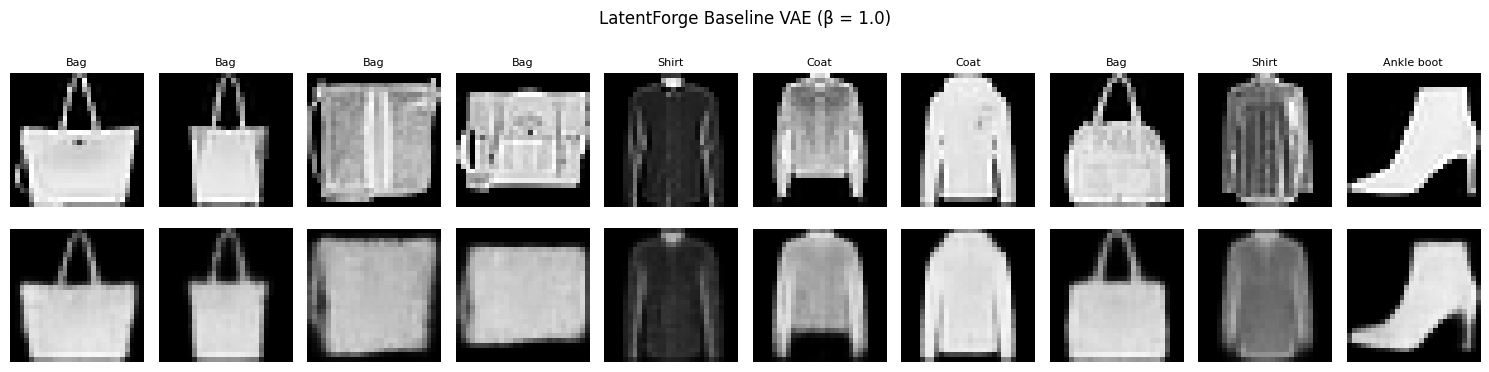

Reconstruction figure saved to: /content/drive/MyDrive/LatentForge/figures/baseline_reconstructions.png


In [ ]:
# Step 11: Visualize original and reconstructed images

import matplotlib.pyplot as plt
import torch

# 1. Get a batch of validation images
images, labels = next(iter(val_loader))
images = images.to(device)

# 2. Generate deterministic reconstructions
baseline_model.eval()

with torch.no_grad():
    mu, logvar = baseline_model.encode(images)
    reconstructions = baseline_model.decode(mu)

# 3. Display original and reconstructed images
num_images = 10

fig, axes = plt.subplots(2, num_images, figsize=(15, 4))

for i in range(num_images):
    # Original image
    axes[0, i].imshow(
        images[i].cpu().squeeze().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[0, i].set_title(class_names[labels[i].item()], fontsize=8)
    axes[0, i].axis("off")

    # Reconstructed image
    axes[1, i].imshow(
        reconstructions[i].cpu().squeeze().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=10)
axes[1, 0].set_ylabel("Reconstructed", fontsize=10)

plt.suptitle("LatentForge Baseline VAE (β = 1.0)")
plt.tight_layout()

# 4. Save the figure to Google Drive
reconstruction_path = os.path.join(
    FIGURES_DIR, "baseline_reconstructions.png"
)
plt.savefig(reconstruction_path, dpi=200, bbox_inches="tight")
plt.show()

print("Reconstruction figure saved to:", reconstruction_path)

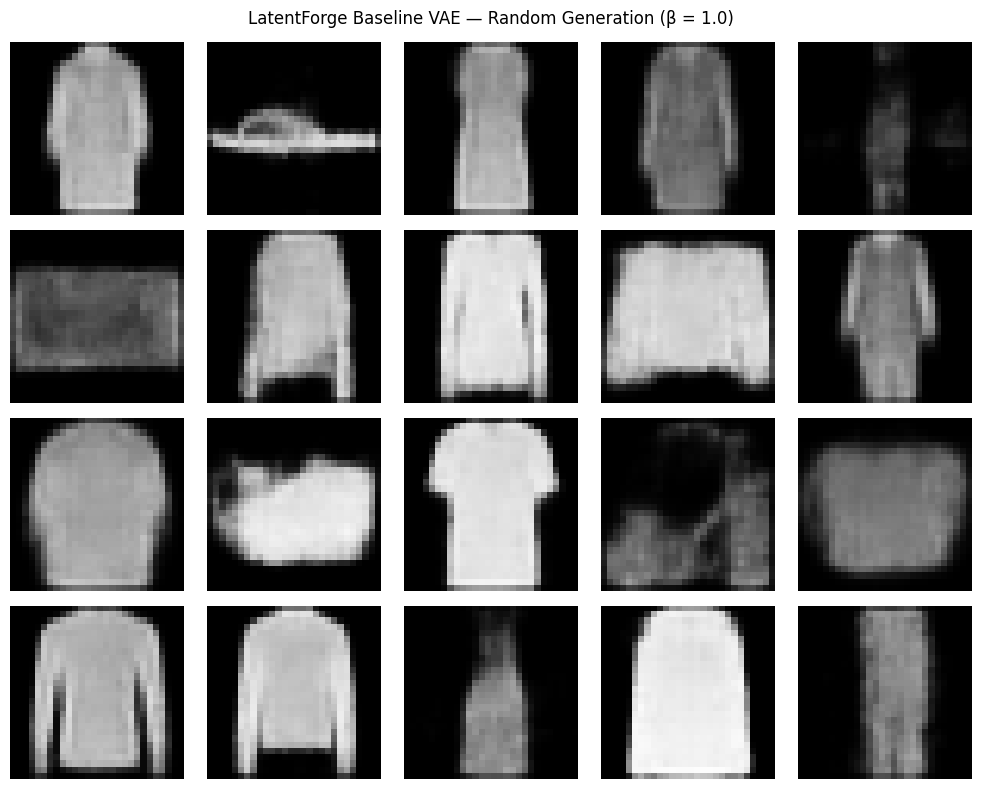

Generated samples saved to: /content/drive/MyDrive/LatentForge/figures/baseline_generated_samples.png


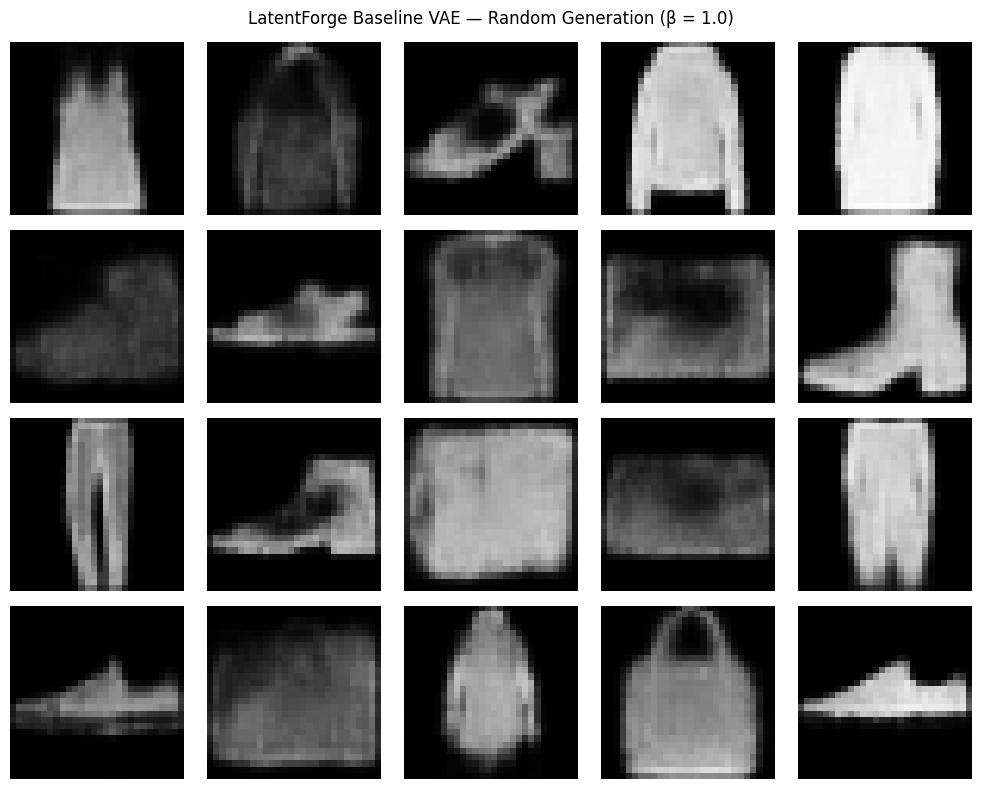

Generated samples saved to: /content/drive/MyDrive/LatentForge/figures/baseline_generated_samples.png


In [ ]:
# Step 12: Generate new images from random latent vectors

import matplotlib.pyplot as plt
import torch
import os

# 1. Set the model to evaluation mode
baseline_model.eval()

# 2. Sample random vectors from the standard normal distribution
num_images = 20

with torch.no_grad():
    random_latents = torch.randn(
        num_images, LATENT_DIM, device=device
    )

    generated_images = baseline_model.decode(random_latents)

# 3. Display the generated images
fig, axes = plt.subplots(4, 5, figsize=(10, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(
        generated_images[i].cpu().squeeze().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    ax.axis("off")

plt.suptitle("LatentForge Baseline VAE — Random Generation (β = 1.0)")
plt.tight_layout()

# 4. Save the figure
generation_path = os.path.join(
    FIGURES_DIR, "baseline_generated_samples.png"
)

plt.savefig(generation_path, dpi=200, bbox_inches="tight")
plt.show()

print("Generated samples saved to:", generation_path)# Step 12: Generate new images from random latent vectors

import matplotlib.pyplot as plt
import torch
import os

# 1. Set the model to evaluation mode
baseline_model.eval()

# 2. Sample random vectors from the standard normal distribution
num_images = 20

with torch.no_grad():
    random_latents = torch.randn(
        num_images, LATENT_DIM, device=device
    )

    generated_images = baseline_model.decode(random_latents)

# 3. Display the generated images
fig, axes = plt.subplots(4, 5, figsize=(10, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(
        generated_images[i].cpu().squeeze().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    ax.axis("off")

plt.suptitle("LatentForge Baseline VAE — Random Generation (β = 1.0)")
plt.tight_layout()

# 4. Save the figure
generation_path = os.path.join(
    FIGURES_DIR, "baseline_generated_samples.png"
)

plt.savefig(generation_path, dpi=200, bbox_inches="tight")
plt.show()

print("Generated samples saved to:", generation_path)

In [ ]:
# Step 13: Final test-set evaluation of the baseline VAE

import json
import os
import torch

# 1. Load the best baseline checkpoint
checkpoint = torch.load(
    BASELINE_CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

baseline_model.load_state_dict(checkpoint["model_state_dict"])
baseline_model.to(device)
baseline_model.eval()

# 2. Evaluate on the official test set
# evaluate() uses the latent mean for deterministic reconstruction.
baseline_test_metrics = evaluate(
    baseline_model,
    test_loader,
    beta=BASELINE_BETA,
    device=device
)

# 3. Display the results
print("BASELINE VAE — TEST SET RESULTS")
print("--------------------------------")
print("Checkpoint epoch:", checkpoint["epoch"])
print("Beta:", BASELINE_BETA)
print("Test loss:", round(baseline_test_metrics["loss"], 4))
print(
    "Test reconstruction loss:",
    round(baseline_test_metrics["reconstruction"], 4)
)
print("Test KL divergence:", round(baseline_test_metrics["kl"], 4))

# 4. Save the test results to Google Drive
baseline_test_results = {
    "experiment": "baseline_vae",
    "beta": BASELINE_BETA,
    "checkpoint_epoch": checkpoint["epoch"],
    "test_loss": baseline_test_metrics["loss"],
    "test_reconstruction": baseline_test_metrics["reconstruction"],
    "test_kl": baseline_test_metrics["kl"]
}

baseline_test_path = os.path.join(
    RESULTS_DIR, "baseline_test_results.json"
)

with open(baseline_test_path, "w") as file:
    json.dump(baseline_test_results, file, indent=2)

print("\nTest results saved to:", baseline_test_path)

BASELINE VAE — TEST SET RESULTS
--------------------------------
Checkpoint epoch: 27
Beta: 1.0
Test loss: 235.3118
Test reconstruction loss: 222.0716
Test KL divergence: 13.2402

Test results saved to: /content/drive/MyDrive/LatentForge/results/baseline_test_results.json


In [ ]:
# Step 14: Check that LatentForge is ready for the next experiment

import os
import json

print("Device:", device)
print("Latent dimension:", LATENT_DIM)
print("Batch size:", BATCH_SIZE)
print("Training epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Fixed beta values:", FIXED_BETA_VALUES)

print("\nBaseline checkpoint exists:",
      os.path.exists(BASELINE_CHECKPOINT_PATH))

print("Baseline history exists:",
      os.path.exists(BASELINE_HISTORY_PATH))

print("Baseline test results exist:",
      os.path.exists(baseline_test_path))

Device: cuda
Latent dimension: 16
Batch size: 128
Training epochs: 30
Learning rate: 0.001
Fixed beta values: [0.5, 2.0, 4.0]

Baseline checkpoint exists: True
Baseline history exists: True
Baseline test results exist: True


In [ ]:
# Step 15: Reusable training function for fixed-beta experiments

def run_fixed_beta_experiment(beta):
    print("\n" + "=" * 60)
    print(f"Starting fixed-beta experiment: beta = {beta}")
    print("=" * 60)

    # 1. Reset random seeds for reproducibility
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    # 2. Create a fresh model and optimizer
    experiment_model = VAE(latent_dim=LATENT_DIM).to(device)

    experiment_optimizer = torch.optim.Adam(
        experiment_model.parameters(),
        lr=LEARNING_RATE
    )

    # 3. Create separate files for this experiment
    beta_tag = str(beta).replace(".", "_")

    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        f"fixed_beta_{beta_tag}_best.pt"
    )

    history_path = os.path.join(
        RESULTS_DIR,
        f"fixed_beta_{beta_tag}_history.json"
    )

    # 4. Initialize experiment tracking
    history = []
    best_val_loss = float("inf")
    best_epoch = 0

    # 5. Train for the configured number of epochs
    for epoch in range(1, EPOCHS + 1):

        train_metrics = train_one_epoch(
            experiment_model,
            train_loader,
            experiment_optimizer,
            beta,
            device
        )

        val_metrics = evaluate(
            experiment_model,
            val_loader,
            beta,
            device
        )

        epoch_metrics = {
            "epoch": epoch,
            "beta": beta,
            "train_loss": train_metrics["loss"],
            "train_reconstruction": train_metrics["reconstruction"],
            "train_kl": train_metrics["kl"],
            "val_loss": val_metrics["loss"],
            "val_reconstruction": val_metrics["reconstruction"],
            "val_kl": val_metrics["kl"]
        }

        history.append(epoch_metrics)

        # 6. Save the best checkpoint based on validation loss
        if val_metrics["loss"] < best_val_loss:
            best_val_loss = val_metrics["loss"]
            best_epoch = epoch

            save_checkpoint(
                experiment_model,
                experiment_optimizer,
                epoch,
                beta,
                best_val_loss,
                checkpoint_path,
                SEED
            )

        # 7. Save history after every epoch
        with open(history_path, "w") as file:
            json.dump(history, file, indent=2)

        print(
            f"Epoch [{epoch:02d}/{EPOCHS}] | "
            f"Train Loss: {train_metrics['loss']:.4f} | "
            f"Train Recon: {train_metrics['reconstruction']:.4f} | "
            f"Train KL: {train_metrics['kl']:.4f} | "
            f"Val Loss: {val_metrics['loss']:.4f} | "
            f"Val Recon: {val_metrics['reconstruction']:.4f} | "
            f"Val KL: {val_metrics['kl']:.4f}"
        )

    print("\n" + "=" * 60)
    print(f"EXPERIMENT COMPLETED: beta = {beta}")
    print(f"Best epoch: {best_epoch}")
    print(f"Best validation loss: {best_val_loss:.4f}")
    print(f"Checkpoint: {checkpoint_path}")
    print(f"History: {history_path}")
    print("=" * 60)

    return {
        "beta": beta,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "checkpoint_path": checkpoint_path,
        "history_path": history_path
    }


print("Fixed-beta training function defined successfully.")

Fixed-beta training function defined successfully.


In [ ]:
# Step 16: Run the fixed-beta experiment with beta = 0.5

results_beta_05 = run_fixed_beta_experiment(beta=0.5)


Starting fixed-beta experiment: beta = 0.5
Epoch [01/30] | Train Loss: 292.4372 | Train Recon: 284.7263 | Train KL: 15.4217 | Val Loss: 249.8679 | Val Recon: 240.4353 | Val KL: 18.8653
Epoch [02/30] | Train Loss: 245.9204 | Train Recon: 236.5826 | Train KL: 18.6755 | Val Loss: 240.2698 | Val Recon: 230.7491 | Val KL: 19.0414
Epoch [03/30] | Train Loss: 240.0430 | Train Recon: 230.6742 | Train KL: 18.7376 | Val Loss: 236.5668 | Val Recon: 227.2306 | Val KL: 18.6725
Epoch [04/30] | Train Loss: 237.2188 | Train Recon: 227.9118 | Train KL: 18.6139 | Val Loss: 234.5376 | Val Recon: 225.1584 | Val KL: 18.7585
Epoch [05/30] | Train Loss: 235.3616 | Train Recon: 226.0407 | Train KL: 18.6416 | Val Loss: 233.0631 | Val Recon: 223.8534 | Val KL: 18.4194
Epoch [06/30] | Train Loss: 234.1876 | Train Recon: 224.8313 | Train KL: 18.7127 | Val Loss: 232.3088 | Val Recon: 222.8604 | Val KL: 18.8967
Epoch [07/30] | Train Loss: 233.2125 | Train Recon: 223.8069 | Train KL: 18.8112 | Val Loss: 231.8817 | 

In [ ]:
# ============================================================
# STEP 9.1: INITIALIZE FIXED-BETA EXPERIMENT (BETA = 2.0)
# ============================================================

# Reset random seeds for a reproducible starting point
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Experiment configuration
BETA = 2.0

# Create a fresh model and optimizer
beta2_model = VAE(latent_dim=LATENT_DIM).to(device)

beta2_optimizer = torch.optim.Adam(
    beta2_model.parameters(),
    lr=LEARNING_RATE
)

# Separate checkpoint and history files
BETA2_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR, "fixed_beta_2_0_best.pt"
)

BETA2_HISTORY_PATH = os.path.join(
    RESULTS_DIR, "fixed_beta_2_0_history.json"
)

# Initialize tracking variables
beta2_history = []
best_beta2_val_loss = float("inf")
best_beta2_epoch = 0

print("Fixed-beta experiment initialized successfully.")
print("Beta:", BETA)
print("Epochs:", EPOCHS)
print("Device:", device)
print("Checkpoint:", BETA2_CHECKPOINT_PATH)
print("History:", BETA2_HISTORY_PATH)

Fixed-beta experiment initialized successfully.
Beta: 2.0
Epochs: 30
Device: cuda
Checkpoint: /content/drive/MyDrive/LatentForge/checkpoints/fixed_beta_2_0_best.pt
History: /content/drive/MyDrive/LatentForge/results/fixed_beta_2_0_history.json


In [ ]:
# ============================================================

# STEP 9.2: TRAIN FIXED-BETA VAE (BETA = 2.0)

# ============================================================

for epoch in range(1, EPOCHS + 1):

    train_metrics = train_one_epoch(
      beta2_model,
      train_loader,
      beta2_optimizer,
      BETA,
      device
    )

    val_metrics = evaluate(
      beta2_model,
      val_loader,
      BETA,
      device
    )

# Store metrics for later analysis
epoch_record = {
    "epoch": epoch,
    "beta": BETA,
    "train_loss": train_metrics["loss"],
    "train_reconstruction": train_metrics["reconstruction"],
    "train_kl": train_metrics["kl"],
    "val_loss": val_metrics["loss"],
    "val_reconstruction": val_metrics["reconstruction"],
    "val_kl": val_metrics["kl"]
}

beta2_history.append(epoch_record)

# Save the model whenever validation loss improves
if val_metrics["loss"] < best_beta2_val_loss:
    best_beta2_val_loss = val_metrics["loss"]
    best_beta2_epoch = epoch

    save_checkpoint(
        beta2_model,
        beta2_optimizer,
        epoch,
        BETA,
        best_beta2_val_loss,
        BETA2_CHECKPOINT_PATH,
        SEED
    )

# Save history after every epoch, so progress is preserved
with open(BETA2_HISTORY_PATH, "w") as f:
    json.dump(beta2_history, f, indent=4)

print(
    f"Epoch [{epoch:02d}/{EPOCHS}] | "
    f"Train: {train_metrics['loss']:.4f} | "
    f"Val: {val_metrics['loss']:.4f} | "
    f"Val Recon: {val_metrics['reconstruction']:.4f} | "
    f"Val KL: {val_metrics['kl']:.4f}"
)

print("\nFixed-beta experiment completed!")
print(f"Beta: {BETA}")
print(f"Best epoch: {best_beta2_epoch}")
print(f"Best validation loss: {best_beta2_val_loss:.4f}")
print(f"Checkpoint saved: {BETA2_CHECKPOINT_PATH}")
print(f"History saved: {BETA2_HISTORY_PATH}")


IndentationError: expected an indented block after 'for' statement on line 7 (1994235935.py, line 9)

In [ ]:
# ============================================================

# STEP 9.2: TRAIN FIXED-BETA VAE (BETA = 2.0)

# ============================================================

for epoch in range(1, EPOCHS + 1):


      train_metrics = train_one_epoch(
          beta2_model,
          train_loader,
          beta2_optimizer,
          BETA,
          device
      )

      val_metrics = evaluate(
          beta2_model,
          val_loader,
          BETA,
          device
      )

      # Store metrics for later analysis
      epoch_record = {
          "epoch": epoch,
          "beta": BETA,
          "train_loss": train_metrics["loss"],
          "train_reconstruction": train_metrics["reconstruction"],
          "train_kl": train_metrics["kl"],
          "val_loss": val_metrics["loss"],
          "val_reconstruction": val_metrics["reconstruction"],
          "val_kl": val_metrics["kl"]
      }

      beta2_history.append(epoch_record)

      # Save the model whenever validation loss improves
      if val_metrics["loss"] < best_beta2_val_loss:
          best_beta2_val_loss = val_metrics["loss"]
          best_beta2_epoch = epoch

          save_checkpoint(
              beta2_model,
              beta2_optimizer,
              epoch,
              BETA,
              best_beta2_val_loss,
              BETA2_CHECKPOINT_PATH,
              SEED
          )

      # Save history after every epoch
      with open(BETA2_HISTORY_PATH, "w") as f:
          json.dump(beta2_history, f, indent=4)

      print(
          f"Epoch [{epoch:02d}/{EPOCHS}] | "
          f"Train: {train_metrics['loss']:.4f} | "
          f"Val: {val_metrics['loss']:.4f} | "
          f"Val Recon: {val_metrics['reconstruction']:.4f} | "
          f"Val KL: {val_metrics['kl']:.4f}"
      )


print("\nFixed-beta experiment completed!")
print(f"Beta: {BETA}")
print(f"Best epoch: {best_beta2_epoch}")
print(f"Best validation loss: {best_beta2_val_loss:.4f}")
print(f"Checkpoint saved: {BETA2_CHECKPOINT_PATH}")
print(f"History saved: {BETA2_HISTORY_PATH}")


Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a64a21e8c20><function _MultiProcessingDataLoaderIter.__del__ at 0x7a64a21e8c20>

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Traceback (most recent call last):
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
self._shutdown_workers()    self._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
        if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
if w.is_alive():    assert self._parent_pid == os.getpid(), 'can only test a child process'

AssertionError  File "/usr/lib/python3.13/multiprocessing/proce

Epoch [01/30] | Train: 251.0076 | Val: 246.9471 | Val Recon: 228.5119 | Val KL: 9.2176
Epoch [02/30] | Train: 250.8633 | Val: 246.7154 | Val Recon: 227.3769 | Val KL: 9.6692
Epoch [03/30] | Train: 250.6059 | Val: 246.0307 | Val Recon: 227.3277 | Val KL: 9.3515
Epoch [04/30] | Train: 250.4703 | Val: 245.5993 | Val Recon: 227.2168 | Val KL: 9.1913
Epoch [05/30] | Train: 250.3327 | Val: 246.2142 | Val Recon: 227.0977 | Val KL: 9.5582
Epoch [06/30] | Train: 250.1483 | Val: 246.6746 | Val Recon: 226.6509 | Val KL: 10.0118
Epoch [07/30] | Train: 250.0149 | Val: 245.5112 | Val Recon: 226.8745 | Val KL: 9.3183
Epoch [08/30] | Train: 249.9079 | Val: 245.7812 | Val Recon: 226.7199 | Val KL: 9.5306
Epoch [09/30] | Train: 249.8145 | Val: 245.8828 | Val Recon: 226.3657 | Val KL: 9.7585
Epoch [10/30] | Train: 249.6834 | Val: 245.5112 | Val Recon: 226.1327 | Val KL: 9.6893
Epoch [11/30] | Train: 249.4815 | Val: 244.9772 | Val Recon: 226.2808 | Val KL: 9.3482
Epoch [12/30] | Train: 249.4396 | Val: 245

In [ ]:
# Step 17: Run the fixed-beta experiment for beta = 4.0

beta4_results = run_fixed_beta_experiment(beta=4.0)


Starting fixed-beta experiment: beta = 4.0
Epoch [01/30] | Train Loss: 318.9033 | Train Recon: 300.8882 | Train KL: 4.5038 | Val Loss: 277.5462 | Val Recon: 254.5787 | Val KL: 5.7419
Epoch [02/30] | Train Loss: 277.9861 | Train Recon: 254.5262 | Train KL: 5.8650 | Val Loss: 268.8690 | Val Recon: 244.7836 | Val KL: 6.0213
Epoch [03/30] | Train Loss: 274.1035 | Train Recon: 249.8482 | Train KL: 6.0638 | Val Loss: 265.2998 | Val Recon: 241.3515 | Val KL: 5.9871
Epoch [04/30] | Train Loss: 272.3083 | Train Recon: 247.8036 | Train KL: 6.1262 | Val Loss: 264.0322 | Val Recon: 239.5868 | Val KL: 6.1113
Epoch [05/30] | Train Loss: 271.1237 | Train Recon: 246.4580 | Train KL: 6.1664 | Val Loss: 263.8315 | Val Recon: 238.4489 | Val KL: 6.3457
Epoch [06/30] | Train Loss: 270.2635 | Train Recon: 245.3815 | Train KL: 6.2205 | Val Loss: 263.7748 | Val Recon: 237.8306 | Val KL: 6.4861
Epoch [07/30] | Train Loss: 269.6254 | Train Recon: 244.4816 | Train KL: 6.2860 | Val Loss: 262.1151 | Val Recon: 23

In [ ]:
# ============================================================
# STEP 18: INITIALIZE KL WARM-UP EXPERIMENT
# ============================================================

# Reset random seeds
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Create a fresh model and optimizer
warmup_model = VAE(latent_dim=LATENT_DIM).to(device)

warmup_optimizer = torch.optim.Adam(
    warmup_model.parameters(),
    lr=LEARNING_RATE
)

# Warm-up configuration
WARMUP_EPOCHS = 10
MAX_BETA = 1.0

# Separate output files
WARMUP_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "kl_warmup_best.pt"
)

WARMUP_HISTORY_PATH = os.path.join(
    RESULTS_DIR,
    "kl_warmup_history.json"
)

# Initialize tracking
warmup_history = []
best_warmup_val_loss = float("inf")
best_warmup_epoch = 0

print("KL warm-up experiment initialized successfully.")
print("Warm-up epochs:", WARMUP_EPOCHS)
print("Maximum beta:", MAX_BETA)
print("Total epochs:", EPOCHS)
print("Device:", device)
print("Checkpoint:", WARMUP_CHECKPOINT_PATH)
print("History:", WARMUP_HISTORY_PATH)

KL warm-up experiment initialized successfully.
Warm-up epochs: 10
Maximum beta: 1.0
Total epochs: 30
Device: cuda
Checkpoint: /content/drive/MyDrive/LatentForge/checkpoints/kl_warmup_best.pt
History: /content/drive/MyDrive/LatentForge/results/kl_warmup_history.json


In [ ]:
# ============================================================

# STEP 19: TRAIN VAE WITH KL WARM-UP

# ============================================================

for epoch in range(1, EPOCHS + 1):


        # Gradually increase beta during the warm-up period
        beta = min(MAX_BETA, epoch / WARMUP_EPOCHS)

        train_metrics = train_one_epoch(
            warmup_model,
            train_loader,
            warmup_optimizer,
            beta,
            device
        )

        val_metrics = evaluate(
            warmup_model,
            val_loader,
            beta,
            device
        )

        # Record metrics for this epoch
        epoch_metrics = {
            "epoch": epoch,
            "beta": beta,
            "train_loss": train_metrics["loss"],
            "train_reconstruction": train_metrics["reconstruction"],
            "train_kl": train_metrics["kl"],
            "val_loss": val_metrics["loss"],
            "val_reconstruction": val_metrics["reconstruction"],
            "val_kl": val_metrics["kl"]
        }

        warmup_history.append(epoch_metrics)

        # Save the best checkpoint based on validation loss
        if val_metrics["loss"] < best_warmup_val_loss:
            best_warmup_val_loss = val_metrics["loss"]
            best_warmup_epoch = epoch

            save_checkpoint(
                warmup_model,
                warmup_optimizer,
                epoch,
                beta,
                best_warmup_val_loss,
                WARMUP_CHECKPOINT_PATH,
                SEED
            )

        # Save history after every epoch
        with open(WARMUP_HISTORY_PATH, "w") as file:
            json.dump(warmup_history, file, indent=2)

        print(
            f"Epoch [{epoch:02d}/{EPOCHS}] | "
            f"Beta: {beta:.2f} | "
            f"Train Loss: {train_metrics['loss']:.4f} | "
            f"Val Loss: {val_metrics['loss']:.4f} | "
            f"Val Recon: {val_metrics['reconstruction']:.4f} | "
            f"Val KL: {val_metrics['kl']:.4f}"
        )

# Final experiment summary

print("\n" + "=" * 60)
print("KL WARM-UP EXPERIMENT COMPLETED")
print(f"Best epoch: {best_warmup_epoch}")
print(f"Best validation loss: {best_warmup_val_loss:.4f}")
print(f"Checkpoint: {WARMUP_CHECKPOINT_PATH}")
print(f"History: {WARMUP_HISTORY_PATH}")
print("=" * 60)


Epoch [01/30] | Beta: 0.10 | Train Loss: 281.5261 | Val Loss: 239.9944 | Val Recon: 236.0263 | Val KL: 39.6809
Epoch [02/30] | Beta: 0.20 | Train Loss: 238.5431 | Val Loss: 234.2247 | Val Recon: 227.8852 | Val KL: 31.6972
Epoch [03/30] | Beta: 0.30 | Train Loss: 235.9951 | Val Loss: 232.3704 | Val Recon: 224.3516 | Val KL: 26.7293
Epoch [04/30] | Beta: 0.40 | Train Loss: 235.4557 | Val Loss: 232.4130 | Val Recon: 222.4291 | Val KL: 24.9598
Epoch [05/30] | Beta: 0.50 | Train Loss: 235.7792 | Val Loss: 232.9729 | Val Recon: 221.5807 | Val KL: 22.7844
Epoch [06/30] | Beta: 0.60 | Train Loss: 236.5009 | Val Loss: 233.9330 | Val Recon: 221.0561 | Val KL: 21.4615
Epoch [07/30] | Beta: 0.70 | Train Loss: 237.5237 | Val Loss: 234.0826 | Val Recon: 219.9852 | Val KL: 20.1392
Epoch [08/30] | Beta: 0.80 | Train Loss: 238.5915 | Val Loss: 234.2696 | Val Recon: 219.3458 | Val KL: 18.6548
Epoch [09/30] | Beta: 0.90 | Train Loss: 239.7574 | Val Loss: 235.5992 | Val Recon: 219.4746 | Val KL: 17.9163
E

In [ ]:

print("Device:", device)
print("Model class available:", "VAE" in globals())
print("Training function available:", "train_one_epoch" in globals())
print("Evaluation function available:", "evaluate" in globals())
print("Training loader available:", "train_loader" in globals())
print("Validation loader available:", "val_loader" in globals())
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Results directory:", RESULTS_DIR)
print("Epochs:", EPOCHS)
print("Latent dimension:", LATENT_DIM)


Device: cuda
Model class available: True
Training function available: True
Evaluation function available: True
Training loader available: True
Validation loader available: True
Checkpoint directory: /content/drive/MyDrive/LatentForge/checkpoints
Results directory: /content/drive/MyDrive/LatentForge/results
Epochs: 30
Latent dimension: 16


In [ ]:

# Adaptive-beta experiment configuration

ADAPTIVE_WARMUP_EPOCHS = 10

ADAPTIVE_MIN_BETA = 0.1
ADAPTIVE_MAX_BETA = 2.0

ADAPTIVE_BETA_STEP = 0.1
ADAPTIVE_RECON_TOLERANCE = 0.01
ADAPTIVE_REQUIRED_CONSECUTIVE_EPOCHS = 2

ADAPTIVE_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR, "adaptive_beta_best.pt"
)

ADAPTIVE_HISTORY_PATH = os.path.join(
    RESULTS_DIR, "adaptive_beta_history.json"
)

print("Adaptive-beta configuration ready!")
print("Warm-up epochs:", ADAPTIVE_WARMUP_EPOCHS)
print("Beta range:", ADAPTIVE_MIN_BETA, "to", ADAPTIVE_MAX_BETA)
print("Beta adjustment step:", ADAPTIVE_BETA_STEP)
print("Reconstruction tolerance:", ADAPTIVE_RECON_TOLERANCE)
print("Required consecutive epochs:",
      ADAPTIVE_REQUIRED_CONSECUTIVE_EPOCHS)
print("Checkpoint:", ADAPTIVE_CHECKPOINT_PATH)
print("History:", ADAPTIVE_HISTORY_PATH)



Adaptive-beta configuration ready!
Warm-up epochs: 10
Beta range: 0.1 to 2.0
Beta adjustment step: 0.1
Reconstruction tolerance: 0.01
Required consecutive epochs: 2
Checkpoint: /content/drive/MyDrive/LatentForge/checkpoints/adaptive_beta_best.pt
History: /content/drive/MyDrive/LatentForge/results/adaptive_beta_history.json


In [ ]:

import random
import json
import os
import numpy as np
import torch

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Create a fresh model and optimizer
adaptive_model = VAE(latent_dim=LATENT_DIM).to(device)

adaptive_optimizer = torch.optim.Adam(
    adaptive_model.parameters(),
    lr=LEARNING_RATE
)

adaptive_history = []
best_val_reconstruction = float("inf")
best_epoch = 0

current_beta = ADAPTIVE_MIN_BETA
previous_val_reconstruction = None

improvement_streak = 0
deterioration_streak = 0

print("=" * 65)
print("STARTING ADAPTIVE-BETA EXPERIMENT")
print("=" * 65)

for epoch in range(1, EPOCHS + 1):

    # Warm-up: beta increases linearly from 0.1 to 1.0
    if epoch <= ADAPTIVE_WARMUP_EPOCHS:
        current_beta = (
            ADAPTIVE_MIN_BETA
            + (1.0 - ADAPTIVE_MIN_BETA)
            * epoch / ADAPTIVE_WARMUP_EPOCHS
        )

    # Train for one epoch using the beta selected for this epoch
    train_metrics = train_one_epoch(
        adaptive_model,
        train_loader,
        adaptive_optimizer,
        current_beta,
        device
    )

    # Evaluate using the existing deterministic evaluation function
    val_metrics = evaluate(
        adaptive_model,
        val_loader,
        current_beta,
        device
    )

    val_recon = val_metrics["reconstruction"]

    # Save the best model based on validation reconstruction loss
    if val_recon < best_val_reconstruction:
        best_val_reconstruction = val_recon
        best_epoch = epoch

        save_checkpoint(
            adaptive_model,
            adaptive_optimizer,
            epoch,
            current_beta,
            val_metrics["loss"],
            ADAPTIVE_CHECKPOINT_PATH,
            SEED
        )

    # Log metrics for this epoch
    epoch_record = {
        "epoch": epoch,
        "beta": current_beta,
        "train_loss": train_metrics["loss"],
        "train_reconstruction": train_metrics["reconstruction"],
        "train_kl": train_metrics["kl"],
        "val_loss": val_metrics["loss"],
        "val_reconstruction": val_recon,
        "val_kl": val_metrics["kl"]
    }

    adaptive_history.append(epoch_record)

    # Save history after every epoch
    with open(ADAPTIVE_HISTORY_PATH, "w") as file:
        json.dump(adaptive_history, file, indent=2)

    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] | "
        f"Beta: {current_beta:.2f} | "
        f"Train Loss: {train_metrics['loss']:.4f} | "
        f"Train Recon: {train_metrics['reconstruction']:.4f} | "
        f"Train KL: {train_metrics['kl']:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val Recon: {val_recon:.4f} | "
        f"Val KL: {val_metrics['kl']:.4f}"
    )

    # Adaptive updates begin after warm-up.
    # The updated beta is used starting in the NEXT epoch.
    if epoch > ADAPTIVE_WARMUP_EPOCHS:

        if previous_val_reconstruction is not None:
            relative_change = (
                val_recon - previous_val_reconstruction
            ) / max(abs(previous_val_reconstruction), 1e-8)

            if relative_change < -ADAPTIVE_RECON_TOLERANCE:
                improvement_streak += 1
                deterioration_streak = 0

            elif relative_change > ADAPTIVE_RECON_TOLERANCE:
                deterioration_streak += 1
                improvement_streak = 0

            else:
                improvement_streak = 0
                deterioration_streak = 0

            if (
                improvement_streak
                >= ADAPTIVE_REQUIRED_CONSECUTIVE_EPOCHS
            ):
                current_beta = min(
                    ADAPTIVE_MAX_BETA,
                    current_beta + ADAPTIVE_BETA_STEP
                )
                improvement_streak = 0
                deterioration_streak = 0
                print(
                    f"  Beta update for next epoch: "
                    f"increased to {current_beta:.2f}"
                )

            elif (
                deterioration_streak
                >= ADAPTIVE_REQUIRED_CONSECUTIVE_EPOCHS
            ):
                current_beta = max(
                    ADAPTIVE_MIN_BETA,
                    current_beta - ADAPTIVE_BETA_STEP
                )
                improvement_streak = 0
                deterioration_streak = 0
                print(
                    f"  Beta update for next epoch: "
                    f"decreased to {current_beta:.2f}"
                )

        previous_val_reconstruction = val_recon

print("\n" + "=" * 65)
print("ADAPTIVE-BETA EXPERIMENT COMPLETED")
print("Best epoch by validation reconstruction:", best_epoch)
print(
    "Best validation reconstruction loss:",
    round(best_val_reconstruction, 4)
)
print("Checkpoint:", ADAPTIVE_CHECKPOINT_PATH)
print("History:", ADAPTIVE_HISTORY_PATH)
print("=" * 65)



STARTING ADAPTIVE-BETA EXPERIMENT
Epoch [01/30] | Beta: 0.19 | Train Loss: 283.7198 | Train Recon: 278.8080 | Train KL: 25.8516 | Val Loss: 243.0281 | Val Recon: 237.5131 | Val KL: 29.0263
Epoch [02/30] | Beta: 0.28 | Train Loss: 240.4908 | Train Recon: 233.2970 | Train KL: 25.6922 | Val Loss: 235.9018 | Val Recon: 228.6452 | Val KL: 25.9163
Epoch [03/30] | Beta: 0.37 | Train Loss: 236.8998 | Train Recon: 228.3317 | Train KL: 23.1570 | Val Loss: 233.7954 | Val Recon: 225.3227 | Val KL: 22.8992
Epoch [04/30] | Beta: 0.46 | Train Loss: 235.8904 | Train Recon: 226.0358 | Train KL: 21.4231 | Val Loss: 233.2497 | Val Recon: 223.3461 | Val KL: 21.5296
Epoch [05/30] | Beta: 0.55 | Train Loss: 235.9248 | Train Recon: 224.7869 | Train KL: 20.2507 | Val Loss: 233.1903 | Val Recon: 222.0576 | Val KL: 20.2411
Epoch [06/30] | Beta: 0.64 | Train Loss: 236.4600 | Train Recon: 224.1274 | Train KL: 19.2697 | Val Loss: 233.7759 | Val Recon: 221.4535 | Val KL: 19.2538
Epoch [07/30] | Beta: 0.73 | Train L

In [ ]:
import os

print("CHECKPOINT FILES")
for filename in sorted(os.listdir(CHECKPOINT_DIR)):
    if filename.endswith(".pt"):
        print(filename)

print("\nHISTORY FILES")
for filename in sorted(os.listdir(RESULTS_DIR)):
    if filename.endswith(".json"):
        print(filename)

CHECKPOINT FILES
adaptive_beta_best.pt
baseline_best.pt
fixed_beta_0_5_best.pt
fixed_beta_2_0_best.pt
fixed_beta_4_0_best.pt
kl_warmup_best.pt

HISTORY FILES
adaptive_beta_history.json
baseline_history.json
baseline_history_backup_before_cleanup.json
baseline_test_results.json
fixed_beta_0_5_history.json
fixed_beta_2_0_history.json
fixed_beta_4_0_history.json
kl_warmup_history.json


In [ ]:
import os
import json
import pandas as pd

history_files = {
    "Baseline (beta=1)": "baseline_history.json",
    "Fixed beta=0.5": "fixed_beta_0_5_history.json",
    "Fixed beta=2.0": "fixed_beta_2_0_history.json",
    "Fixed beta=4.0": "fixed_beta_4_0_history.json",
    "KL warm-up": "kl_warmup_history.json",
    "Adaptive beta": "adaptive_beta_history.json"
}

comparison_rows = []

for experiment_name, filename in history_files.items():
    filepath = os.path.join(RESULTS_DIR, filename)

    with open(filepath, "r") as file:
        history = json.load(file)

    # Select the epoch with the lowest validation reconstruction loss.
    best_row = min(
        history,
        key=lambda row: row["val_reconstruction"]
    )

    comparison_rows.append({
        "Experiment": experiment_name,
        "Best Reconstruction Epoch": best_row["epoch"],
        "Best Val Reconstruction": best_row["val_reconstruction"],
        "KL at Selected Epoch": best_row["val_kl"],
        "Beta at Selected Epoch": best_row.get("beta", None),
        "Total Val Loss at Selected Epoch": best_row["val_loss"]
    })

comparison_df = pd.DataFrame(comparison_rows)

comparison_df = comparison_df.sort_values(
    "Best Val Reconstruction"
).reset_index(drop=True)

print("VALIDATION COMPARISON — LOWER RECONSTRUCTION LOSS IS BETTER")
display(comparison_df.round(4))

VALIDATION COMPARISON — LOWER RECONSTRUCTION LOSS IS BETTER


,Experiment,Best Reconstruction Epoch,Best Val Reconstruction,KL at Selected Epoch,Beta at Selected Epoch,Total Val Loss at Selected Epoch
0,KL warm-up,29,216.8210,16.0151,1.0,232.8361
1,Fixed beta=0.5,29,216.9110,20.0060,0.5,226.9140
2,Adaptive beta,29,217.2489,15.8316,1.0,233.0805
3,Baseline (beta=1),30,220.9626,13.7492,1.0,234.7118
4,Fixed beta=2.0,27,225.0516,9.8452,2.0,244.7420
5,Fixed beta=4.0,30,230.3310,7.1332,4.0,258.8639


In [ ]:

import os
import torch
import pandas as pd

checkpoint_files = {
    "Baseline β=1": "baseline_best.pt",
    "Fixed β=0.5": "fixed_beta_0_5_best.pt",
    "Fixed β=2": "fixed_beta_2_0_best.pt",
    "Fixed β=4": "fixed_beta_4_0_best.pt",
    "KL warm-up": "kl_warmup_best.pt",
    "Adaptive β": "adaptive_beta_best.pt"
}

checkpoint_rows = []

for experiment, filename in checkpoint_files.items():
    path = os.path.join(CHECKPOINT_DIR, filename)

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    checkpoint_rows.append({
        "Experiment": experiment,
        "Saved epoch": checkpoint.get("epoch", "Unknown"),
        "Saved beta": checkpoint.get("beta", "Unknown"),
        "Saved validation loss": checkpoint.get("val_loss", "Unknown"),
        "Latent dimension": checkpoint.get("latent_dim", "Unknown")
    })

display(pd.DataFrame(checkpoint_rows))



,Experiment,Saved epoch,Saved beta,Saved validation loss,Latent dimension
0,Baseline β=1,27,1.0,234.541541,16
1,Fixed β=0.5,29,0.5,226.914030,16
2,Fixed β=2,26,2.0,244.431532,16
3,Fixed β=4,29,4.0,257.522091,16
4,KL warm-up,3,0.3,232.370389,16
5,Adaptive β,29,1.0,233.080502,16


In [ ]:

import os
import torch

checkpoint_files = {
    "Baseline": "baseline_best.pt",
    "Fixed beta 0.5": "fixed_beta_0_5_best.pt",
    "Fixed beta 2.0": "fixed_beta_2_0_best.pt",
    "Fixed beta 4.0": "fixed_beta_4_0_best.pt",
    "KL warm-up": "kl_warmup_best.pt",
    "Adaptive beta": "adaptive_beta_best.pt"
}

for experiment, filename in checkpoint_files.items():
    path = os.path.join(CHECKPOINT_DIR, filename)
    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    print(f"\n{experiment}")
    print("  Epoch:", checkpoint["epoch"])
    print("  Beta:", checkpoint["beta"])
    print("  Stored model weights:",
          len(checkpoint["model_state_dict"]))
    print("  Stored optimizer state:",
          "optimizer_state_dict" in checkpoint)



Baseline
  Epoch: 27
  Beta: 1.0
  Stored model weights: 18
  Stored optimizer state: True

Fixed beta 0.5
  Epoch: 29
  Beta: 0.5
  Stored model weights: 18
  Stored optimizer state: True

Fixed beta 2.0
  Epoch: 26
  Beta: 2.0
  Stored model weights: 18
  Stored optimizer state: True

Fixed beta 4.0
  Epoch: 29
  Beta: 4.0
  Stored model weights: 18
  Stored optimizer state: True

KL warm-up
  Epoch: 3
  Beta: 0.3
  Stored model weights: 18
  Stored optimizer state: True

Adaptive beta
  Epoch: 29
  Beta: 1.0
  Stored model weights: 18
  Stored optimizer state: True


In [ ]:

import os
import torch

checkpoint_files = {
    "Baseline": "baseline_best.pt",
    "Fixed beta 0.5": "fixed_beta_0_5_best.pt",
    "Fixed beta 2.0": "fixed_beta_2_0_best.pt",
    "Fixed beta 4.0": "fixed_beta_4_0_best.pt",
    "KL warm-up": "kl_warmup_best.pt",
    "Adaptive beta": "adaptive_beta_best.pt"
}

loaded_models = {}
checkpoint_metadata = {}

for experiment, filename in checkpoint_files.items():
    checkpoint_path = os.path.join(
        CHECKPOINT_DIR, filename
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    model = VAE(
        latent_dim=checkpoint.get("latent_dim", LATENT_DIM)
    ).to(device)

    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    loaded_models[experiment] = model

    checkpoint_metadata[experiment] = {
        "epoch": checkpoint["epoch"],
        "beta": checkpoint["beta"],
        "val_loss": checkpoint["val_loss"]
    }

print("All available checkpoints loaded successfully.\n")

for experiment, metadata in checkpoint_metadata.items():
    print(
        f"{experiment}: "
        f"epoch={metadata['epoch']}, "
        f"beta={metadata['beta']}"
    )



All available checkpoints loaded successfully.

Baseline: epoch=27, beta=1.0
Fixed beta 0.5: epoch=29, beta=0.5
Fixed beta 2.0: epoch=26, beta=2.0
Fixed beta 4.0: epoch=29, beta=4.0
KL warm-up: epoch=3, beta=0.3
Adaptive beta: epoch=29, beta=1.0


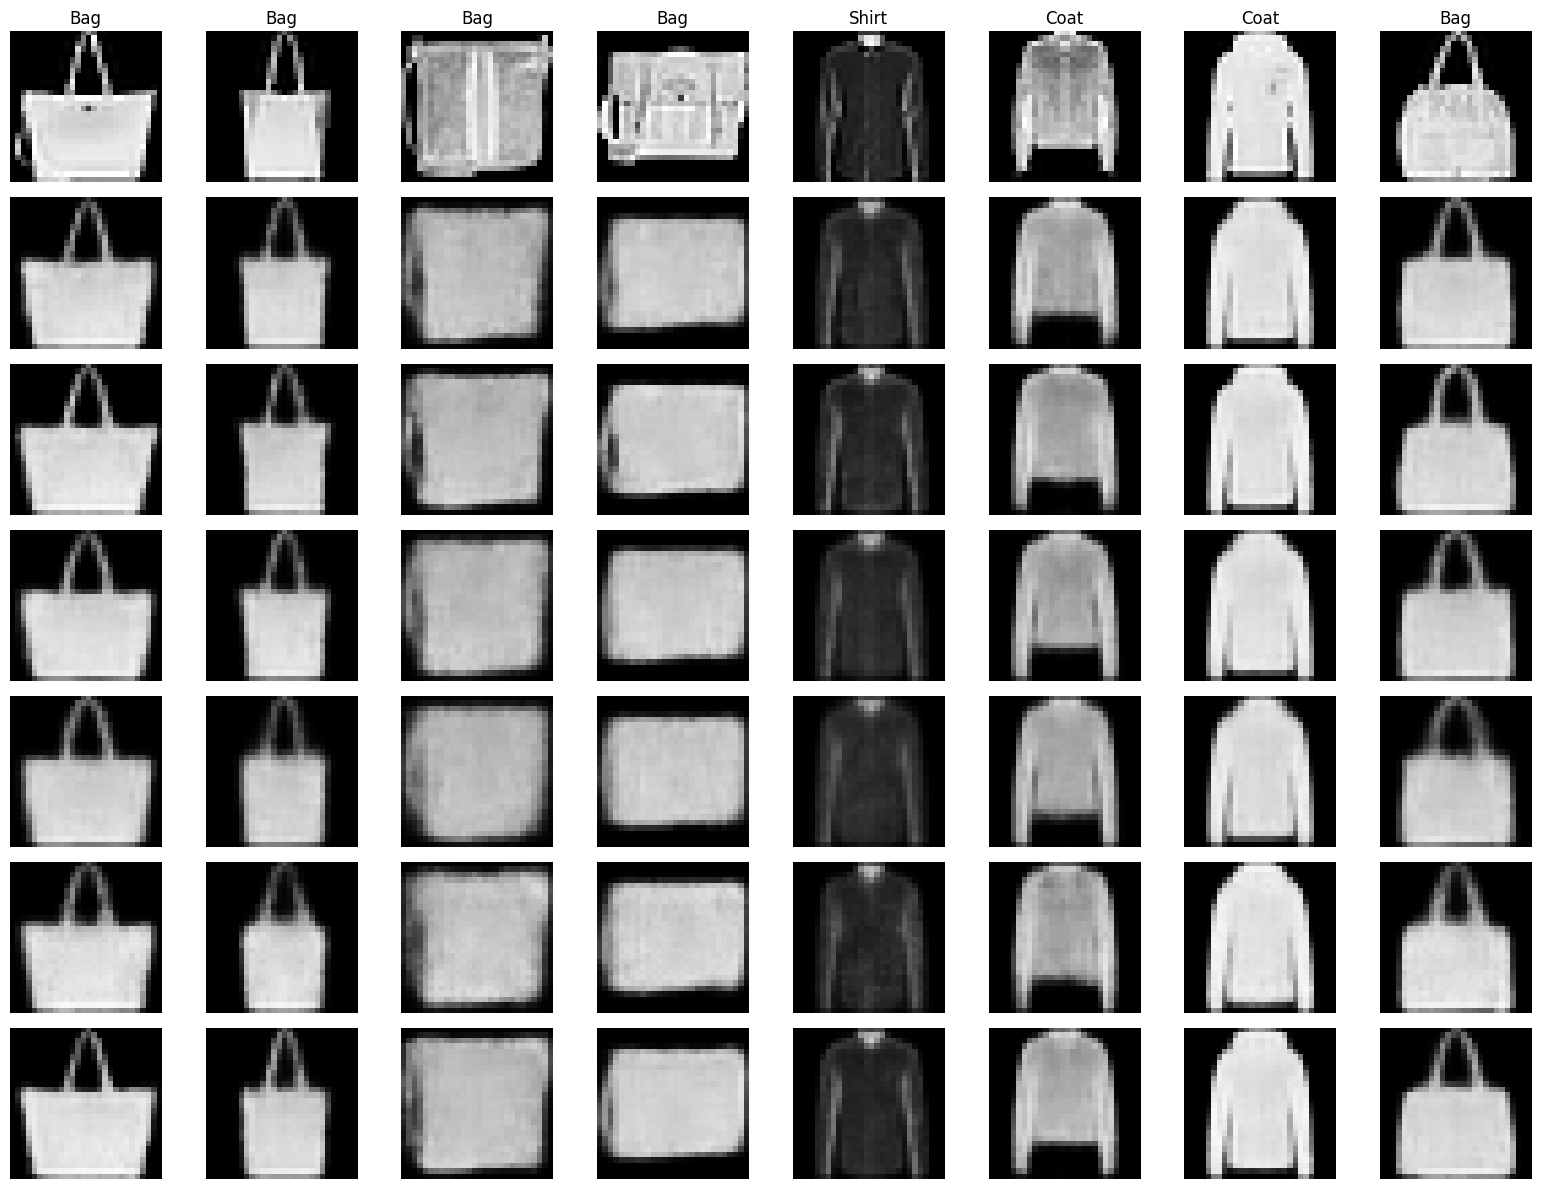

Saved comparison figure to: /content/drive/MyDrive/LatentForge/figures/reconstruction_comparison.png


In [ ]:
import matplotlib.pyplot as plt
import torch
import os

# Get a fixed batch of validation images
images, labels = next(iter(val_loader))
images = images[:8].to(device)
labels = labels[:8]

num_images = images.size(0)
model_names = list(loaded_models.keys())

fig, axes = plt.subplots(
    len(model_names) + 1,
    num_images,
    figsize=(16, 12)
)

# First row: original images
for j in range(num_images):
    axes[0, j].imshow(
        images[j].detach().cpu().squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[0, j].set_title(class_names[labels[j].item()])
    axes[0, j].axis("off")

axes[0, 0].set_ylabel(
    "Original",
    rotation=0,
    labelpad=45,
    fontsize=10
)

# Remaining rows: reconstructions
with torch.no_grad():
    for i, name in enumerate(model_names, start=1):
        model = loaded_models[name]
        mu, logvar = model.encode(images)

        # Deterministic reconstruction for fair visual comparison
        reconstructed = model.decode(mu)

        for j in range(num_images):
            axes[i, j].imshow(
                reconstructed[j].detach().cpu().squeeze(),
                cmap="gray",
                vmin=0,
                vmax=1
            )
            axes[i, j].axis("off")

        axes[i, 0].set_ylabel(
            name,
            rotation=0,
            labelpad=65,
            fontsize=9
        )

plt.tight_layout()

figure_path = os.path.join(
    FIGURES_DIR,
    "reconstruction_comparison.png"
)

plt.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved comparison figure to:", figure_path)

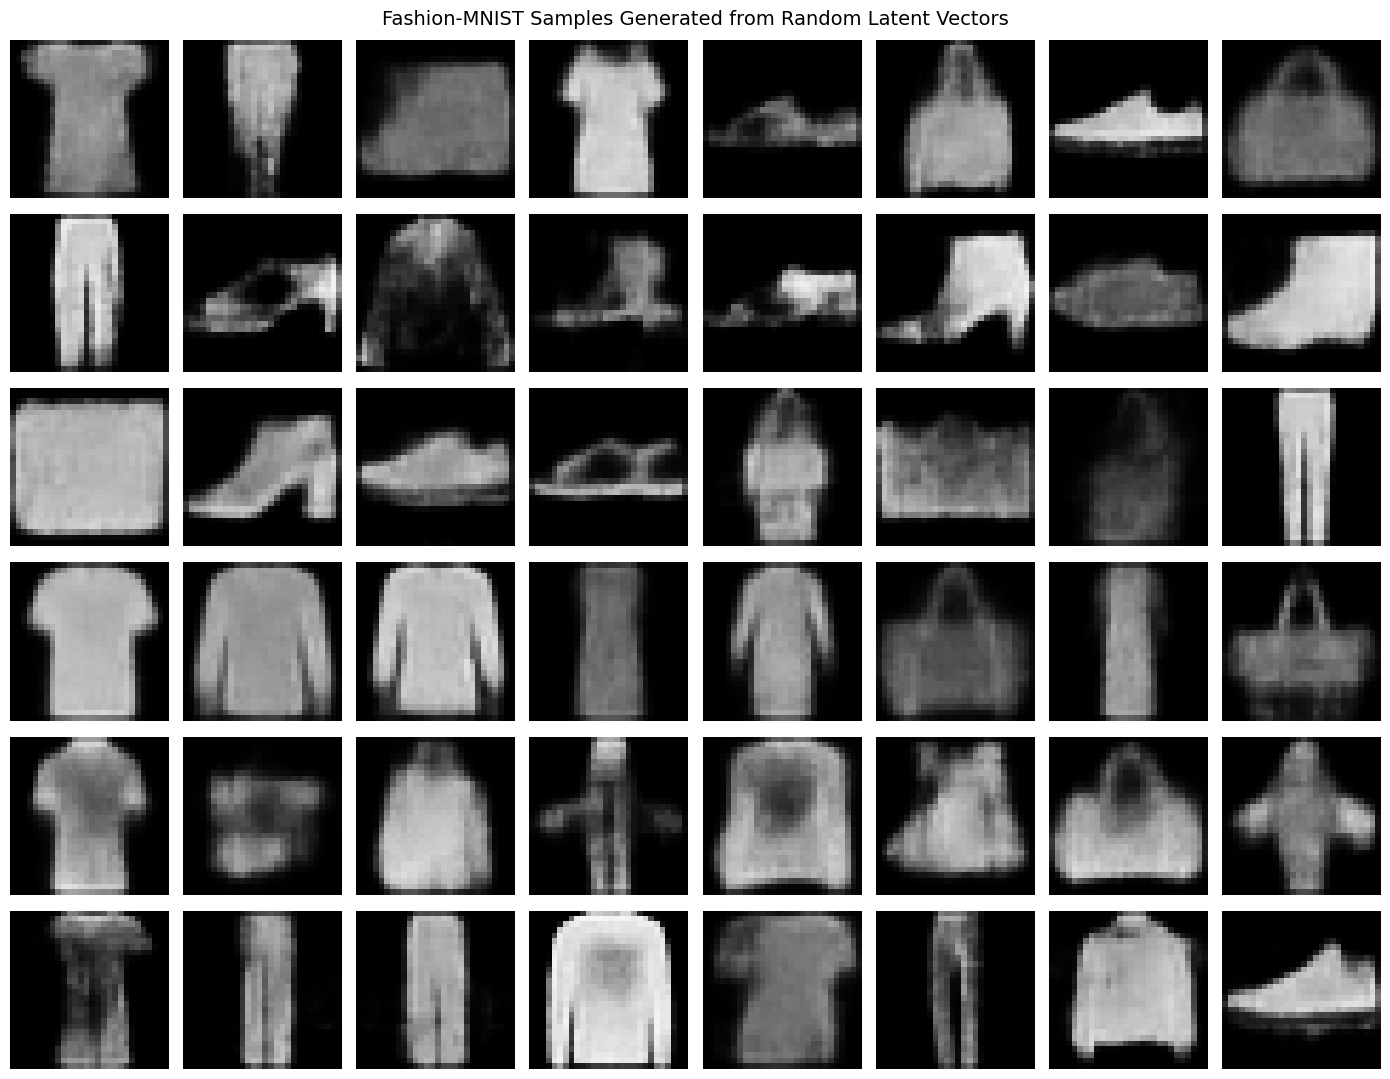

Saved generated samples to: /content/drive/MyDrive/LatentForge/figures/generated_samples_comparison.png


In [ ]:
import matplotlib.pyplot as plt
import torch
import os

num_samples = 8
model_names = list(loaded_models.keys())

fig, axes = plt.subplots(
    len(model_names),
    num_samples,
    figsize=(14, 11)
)

for i, name in enumerate(model_names):
    model = loaded_models[name]
    model.eval()

    # Generate random latent vectors from a standard normal distribution
    z = torch.randn(
        num_samples,
        LATENT_DIM,
        device=device
    )

    with torch.no_grad():
        generated = model.decode(z)

    for j in range(num_samples):
        axes[i, j].imshow(
            generated[j].detach().cpu().squeeze(),
            cmap="gray",
            vmin=0,
            vmax=1
        )
        axes[i, j].axis("off")

    axes[i, 0].set_ylabel(
        name,
        rotation=0,
        labelpad=65,
        fontsize=9
    )

plt.suptitle(
    "Fashion-MNIST Samples Generated from Random Latent Vectors",
    fontsize=14
)

plt.tight_layout()

figure_path = os.path.join(
    FIGURES_DIR,
    "generated_samples_comparison.png"
)

plt.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved generated samples to:", figure_path)

In [ ]:
import json
import os
import pandas as pd

history_files = {
    "Baseline (beta=1)": "baseline_history.json",
    "Fixed beta=0.5": "fixed_beta_0_5_history.json",
    "Fixed beta=2": "fixed_beta_2_0_history.json",
    "Fixed beta=4": "fixed_beta_4_0_history.json",
    "KL warm-up": "kl_warmup_history.json",
    "Adaptive beta": "adaptive_beta_history.json"
}

rows = []

for experiment, filename in history_files.items():
    path = os.path.join(RESULTS_DIR, filename)

    with open(path, "r") as f:
        history = json.load(f)

    # Support histories stored as lists or dictionaries
    if isinstance(history, dict):
        history = history.get("history", history.get("metrics", history))

    df = pd.DataFrame(history)

    best_idx = df["val_reconstruction"].idxmin()
    best = df.loc[best_idx]

    rows.append({
        "Experiment": experiment,
        "Epoch": int(best_idx) + 1,
        "Validation Reconstruction": best["val_reconstruction"],
        "Validation KL": best["val_kl"],
        "Beta": best["beta"]
    })

comparison_df = pd.DataFrame(rows)

print(comparison_df.round(4).to_string(index=False))

       Experiment  Epoch  Validation Reconstruction  Validation KL  Beta
Baseline (beta=1)     30                   220.9626        13.7492   1.0
   Fixed beta=0.5     29                   216.9110        20.0060   0.5
     Fixed beta=2     39                   225.0516         9.8452   2.0
     Fixed beta=4     30                   230.3310         7.1332   4.0
       KL warm-up     29                   216.8210        16.0151   1.0
    Adaptive beta     29                   217.2489        15.8316   1.0


In [ ]:
import json
import os

path = os.path.join(
    RESULTS_DIR,
    "fixed_beta_2_0_history.json"
)

with open(path, "r") as f:
    history = json.load(f)

print("History type:", type(history).__name__)

if isinstance(history, dict):
    print("History keys:", list(history.keys()))

    for key, value in history.items():
        if isinstance(value, list):
            print(f"{key}: {len(value)} entries")
        else:
            print(f"{key}: {value}")

elif isinstance(history, list):
    print("Number of entries:", len(history))
    print("First entry:", history[0])
    print("Last entry:", history[-1])

History type: list
Number of entries: 42
First entry: {'epoch': 1, 'beta': 2.0, 'train_loss': 308.6339342538339, 'train_reconstruction': 294.89807063802084, 'train_kl': 6.86793170175729, 'val_loss': 265.89932486979166, 'val_reconstruction': 249.5635125325521, 'val_kl': 8.167906366984049}
Last entry: {'epoch': 30, 'beta': 2.0, 'train_loss': 248.27624317310475, 'train_reconstruction': 228.82575412778502, 'train_kl': 9.725244375158239, 'val_loss': 245.01237060546876, 'val_reconstruction': 225.05277270507813, 'val_kl': 9.979798629760742}


In [ ]:
import json
import os
import pandas as pd

history_files = {
    "Baseline (beta=1)": "baseline_history.json",
    "Fixed beta=0.5": "fixed_beta_0_5_history.json",
    "Fixed beta=2": "fixed_beta_2_0_history.json",
    "Fixed beta=4": "fixed_beta_4_0_history.json",
    "KL warm-up": "kl_warmup_history.json",
    "Adaptive beta": "adaptive_beta_history.json"
}

rows = []

for experiment, filename in history_files.items():
    path = os.path.join(RESULTS_DIR, filename)

    with open(path, "r") as f:
        history = json.load(f)

    df = pd.DataFrame(history)

    # Keep only valid epochs within the planned 30-epoch experiment
    df = df[df["epoch"].between(1, 30)].copy()

    # If an epoch appears more than once, keep its last recorded entry
    df = df.drop_duplicates(subset="epoch", keep="last")

    # Select the epoch with the lowest validation reconstruction loss
    best_idx = df["val_reconstruction"].idxmin()
    best = df.loc[best_idx]

    rows.append({
        "Experiment": experiment,
        "Epoch": int(best["epoch"]),
        "Validation Reconstruction": best["val_reconstruction"],
        "Validation KL": best["val_kl"],
        "Beta": best["beta"]
    })

comparison_df = pd.DataFrame(rows)

comparison_df = comparison_df.sort_values(
    "Validation Reconstruction"
).reset_index(drop=True)

print(comparison_df.round(4).to_string(index=False))

       Experiment  Epoch  Validation Reconstruction  Validation KL  Beta
       KL warm-up     29                   216.8210        16.0151   1.0
   Fixed beta=0.5     29                   216.9110        20.0060   0.5
    Adaptive beta     29                   217.2489        15.8316   1.0
Baseline (beta=1)     30                   220.9626        13.7492   1.0
     Fixed beta=2     27                   225.0516         9.8452   2.0
     Fixed beta=4     30                   230.3310         7.1332   4.0


In [ ]:
import torch
import pandas as pd

results = []

for name, model in loaded_models.items():
    model.eval()

    total_reconstruction = 0.0
    total_kl = 0.0
    total_images = 0

    with torch.no_grad():
        for images, _ in val_loader:
            images = images.to(device)

            mu, logvar = model.encode(images)
            reconstructed = model.decode(mu)

            # Per-image reconstruction BCE, summed over pixels
            reconstruction = torch.nn.functional.binary_cross_entropy(
                reconstructed,
                images,
                reduction="none"
            ).flatten(1).sum(dim=1)

            # Per-image KL divergence, summed over latent dimensions
            kl = -0.5 * torch.sum(
                1 + logvar - mu.pow(2) - logvar.exp(),
                dim=1
            )

            total_reconstruction += reconstruction.sum().item()
            total_kl += kl.sum().item()
            total_images += images.size(0)

    results.append({
        "Experiment": name,
        "Checkpoint Epoch": checkpoint_metadata[name]["epoch"],
        "Beta": checkpoint_metadata[name]["beta"],
        "Validation Reconstruction": total_reconstruction / total_images,
        "Validation KL": total_kl / total_images
    })

checkpoint_comparison = pd.DataFrame(results)

print(
    checkpoint_comparison.round(4).to_string(index=False)
)

    Experiment  Checkpoint Epoch  Beta  Validation Reconstruction  Validation KL
      Baseline                27   1.0                   221.2267        13.3148
Fixed beta 0.5                29   0.5                   216.9110        20.0060
Fixed beta 2.0                26   2.0                   225.1748         9.6284
Fixed beta 4.0                29   4.0                   231.1169         6.6013
    KL warm-up                 3   0.3                   224.3516        26.7293
 Adaptive beta                29   1.0                   217.2489        15.8316


In [ ]:
if "warmup_model" in globals():
    print("Warm-up model exists in the current runtime.")

    print(
        "Model device:",
        next(warmup_model.parameters()).device
    )

    print(
        "Training mode:",
        warmup_model.training
    )

else:
    print("Warm-up model is not available in the current runtime.")

Warm-up model exists in the current runtime.
Model device: cuda:0
Training mode: False


In [ ]:
import json
import os
import pandas as pd

history_path = os.path.join(
    RESULTS_DIR,
    "kl_warmup_history.json"
)

with open(history_path, "r") as f:
    warmup_history = json.load(f)

history_df = pd.DataFrame(warmup_history)

print("Total history entries:", len(history_df))
print("Recorded epochs:", sorted(history_df["epoch"].unique()))

print("\nLast five recorded epochs:")
print(
    history_df[
        ["epoch", "beta", "val_reconstruction", "val_kl", "val_loss"]
    ].tail(5).to_string(index=False)
)

print("\nBest reconstruction entry:")
best_idx = history_df["val_reconstruction"].idxmin()
print(history_df.loc[best_idx].to_string())

Total history entries: 30
Recorded epochs: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30)]

Last five recorded epochs:
 epoch  beta  val_reconstruction    val_kl   val_loss
    26   1.0          217.297318 17.353017 234.650335
    27   1.0          217.232700 16.026033 233.258733
    28   1.0          217.198186 15.929645 233.127831
    29   1.0          216.821016 16.015057 232.836073
    30   1.0          217.087750 16.240049 233.327799

Best reconstruction entry:
epoch                    29.000000
beta                      1.000000
train_loss              236.694272
train_reconstruction    220.537133
train_kl                 

In [ ]:
import os
import torch

warmup_recovery_path = os.path.join(
    CHECKPOINT_DIR,
    "kl_warmup_runtime_snapshot.pt"
)

torch.save(
    {
        "model_state_dict": warmup_model.state_dict(),
        "latent_dim": LATENT_DIM,
        "note": (
            "Snapshot of the warmup_model currently in Colab memory. "
            "Its exact training epoch has not yet been verified."
        )
    },
    warmup_recovery_path
)

print("Warm-up model snapshot saved to:")
print(warmup_recovery_path)

Warm-up model snapshot saved to:
/content/drive/MyDrive/LatentForge/checkpoints/kl_warmup_runtime_snapshot.pt


In [ ]:
import torch
import torch.nn.functional as F
import pandas as pd
import os

def evaluate_vae(model, loader):
    model.eval()

    total_recon = 0.0
    total_kl = 0.0
    total_images = 0

    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device)

            mu, logvar = model.encode(images)
            reconstructed = model.decode(mu)

            recon = F.binary_cross_entropy(
                reconstructed,
                images,
                reduction="none"
            ).flatten(1).sum(dim=1)

            kl = -0.5 * torch.sum(
                1 + logvar - mu.pow(2) - logvar.exp(),
                dim=1
            )

            total_recon += recon.sum().item()
            total_kl += kl.sum().item()
            total_images += images.size(0)

    return {
        "Validation Reconstruction": total_recon / total_images,
        "Validation KL": total_kl / total_images
    }


# Evaluate the original saved checkpoint
original_path = os.path.join(
    CHECKPOINT_DIR,
    "kl_warmup_best.pt"
)

original_checkpoint = torch.load(
    original_path,
    map_location=device,
    weights_only=True
)

original_model = VAE(
    latent_dim=original_checkpoint.get("latent_dim", LATENT_DIM)
).to(device)

original_model.load_state_dict(
    original_checkpoint["model_state_dict"]
)

# Evaluate both models on identical validation data
original_results = evaluate_vae(original_model, val_loader)
snapshot_results = evaluate_vae(warmup_model, val_loader)

comparison = pd.DataFrame([
    {
        "Model": "Original saved checkpoint",
        "Checkpoint epoch": original_checkpoint["epoch"],
        **original_results
    },
    {
        "Model": "Runtime snapshot",
        "Checkpoint epoch": "Unknown",
        **snapshot_results
    }
])

print(comparison.round(4).to_string(index=False))

                    Model Checkpoint epoch  Validation Reconstruction  Validation KL
Original saved checkpoint                3                   224.3516        26.7293
         Runtime snapshot          Unknown                   217.0878        16.2400


In [ ]:
import os
import json

test_results_path = os.path.join(
    RESULTS_DIR,
    "baseline_test_results.json"
)

if os.path.exists(test_results_path):
    with open(test_results_path, "r") as f:
        test_results = json.load(f)

    print("Existing baseline test results:")
    print(json.dumps(test_results, indent=4))
else:
    print("No baseline test-results file found.")

Existing baseline test results:
{
    "experiment": "baseline_vae",
    "beta": 1.0,
    "checkpoint_epoch": 27,
    "test_loss": 235.3117708984375,
    "test_reconstruction": 222.07158125,
    "test_kl": 13.240189115905762
}


In [ ]:
import torch
import pandas as pd
import numpy as np

def measure_latent_space(model, loader):
    model.eval()

    all_mu = []
    all_logvar = []
    total_kl = 0
    total_images = 0

    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device)

            mu, logvar = model.encode(images)

            kl = -0.5 * torch.sum(
                1 + logvar - mu.pow(2) - logvar.exp(),
                dim=1
            )

            total_kl += kl.sum().item()
            total_images += images.size(0)

            all_mu.append(mu.cpu())
            all_logvar.append(logvar.cpu())

    all_mu = torch.cat(all_mu, dim=0)
    all_logvar = torch.cat(all_logvar, dim=0)

    return {
        "Mean KL per image": total_kl / total_images,
        "Aggregate latent mean": all_mu.mean().item(),
        "Latent mean std": all_mu.std().item(),
        "Mean posterior variance": torch.exp(all_logvar).mean().item()
    }


latent_results = []

for name, model in loaded_models.items():
    metrics = measure_latent_space(model, val_loader)

    latent_results.append({
        "Experiment": name,
        **metrics
    })

latent_df = pd.DataFrame(latent_results)

print(latent_df.round(4).to_string(index=False))

    Experiment  Mean KL per image  Aggregate latent mean  Latent mean std  Mean posterior variance
      Baseline            13.3148                 0.0020           0.6756                   0.5421
Fixed beta 0.5            20.0060                 0.0037           0.7777                   0.3899
Fixed beta 2.0             9.6284                -0.0022           0.5922                   0.6525
Fixed beta 4.0             6.6013                 0.0036           0.5270                   0.7148
    KL warm-up            26.7293                 0.0478           1.0085                   0.0964
 Adaptive beta            15.8316                -0.0159           0.8029                   0.3683


In [ ]:
import torch
import torch.nn.functional as F
import pandas as pd
import os

def measure_generated_diversity(model, num_samples=500):
    model.eval()

    with torch.no_grad():
        z = torch.randn(
            num_samples,
            LATENT_DIM,
            device=device
        )

        generated = model.decode(z).cpu()

        # Flatten each image into a vector
        images = generated.flatten(start_dim=1)

        # Pairwise Euclidean distances
        distances = torch.pdist(images, p=2)

        return {
            "Mean pairwise distance": distances.mean().item(),
            "Distance std": distances.std().item(),
            "Mean pixel intensity": generated.mean().item()
        }


diversity_results = []

for name, model in loaded_models.items():
    metrics = measure_generated_diversity(model)

    diversity_results.append({
        "Experiment": name,
        **metrics
    })

diversity_df = pd.DataFrame(diversity_results)

print(diversity_df.round(4).to_string(index=False))

    Experiment  Mean pairwise distance  Distance std  Mean pixel intensity
      Baseline                  9.2594        2.9589                0.2623
Fixed beta 0.5                  9.1527        2.7652                0.2540
Fixed beta 2.0                  9.4389        3.0688                0.2621
Fixed beta 4.0                  9.2526        3.1042                0.2748
    KL warm-up                  8.5486        2.0178                0.2683
 Adaptive beta                  9.3723        2.9200                0.2747


In [ ]:
print("Models available:")
for name in loaded_models:
    print(name)

print("\nWarm-up model object:")
print("Same object:",
      loaded_models["KL warm-up"] is warmup_model)

print("\nWarm-up snapshot metrics:")
print(evaluate_vae(warmup_model, val_loader))

print("\nWarm-up dictionary model metrics:")
print(evaluate_vae(loaded_models["KL warm-up"], val_loader))

Models available:
Baseline
Fixed beta 0.5
Fixed beta 2.0
Fixed beta 4.0
KL warm-up
Adaptive beta

Warm-up model object:
Same object: False

Warm-up snapshot metrics:
{'Validation Reconstruction': 217.08775130208332, 'Validation KL': 16.240049112955727}

Warm-up dictionary model metrics:
{'Validation Reconstruction': 224.3516083984375, 'Validation KL': 26.729272583007813}


In [ ]:
# Replace the old warm-up model in the comparison dictionary
loaded_models["KL warm-up"] = warmup_model

# Verify that both variables now reference the same model
print(
    "Same model:",
    loaded_models["KL warm-up"] is warmup_model
)

# Verify validation metrics
print(
    "Warm-up validation metrics:",
    evaluate_vae(loaded_models["KL warm-up"], val_loader)
)

Same model: True
Warm-up validation metrics: {'Validation Reconstruction': 217.08775130208332, 'Validation KL': 16.240049112955727}


In [ ]:
diversity_results = []

for name, model in loaded_models.items():
    metrics = measure_generated_diversity(model, num_samples=500)

    diversity_results.append({
        "Experiment": name,
        **metrics
    })

diversity_df = pd.DataFrame(diversity_results)

print(diversity_df.round(4).to_string(index=False))

    Experiment  Mean pairwise distance  Distance std  Mean pixel intensity
      Baseline                  9.5188        3.0082                0.2683
Fixed beta 0.5                  9.4551        2.7888                0.2668
Fixed beta 2.0                  9.5132        3.1290                0.2663
Fixed beta 4.0                  9.4179        3.1249                0.2773
    KL warm-up                  9.3421        2.8813                0.2700
 Adaptive beta                  9.4397        2.8471                0.2672


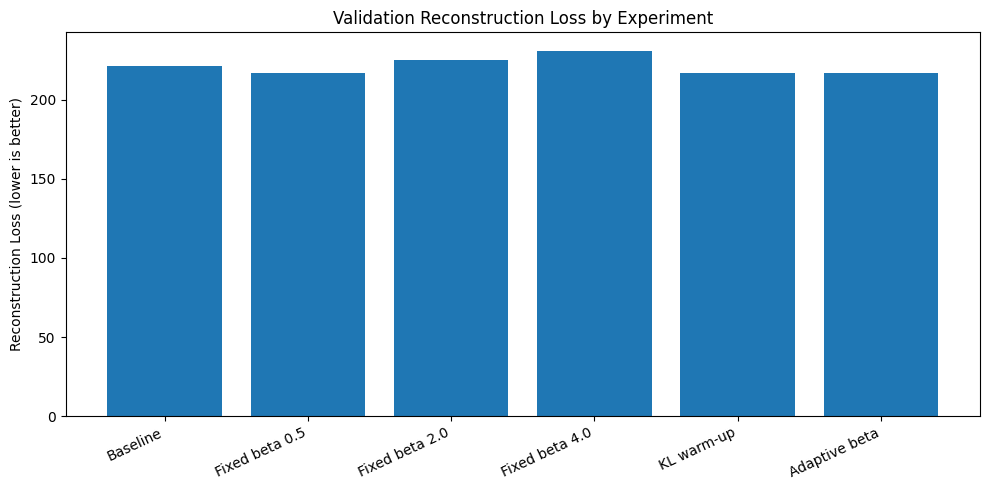

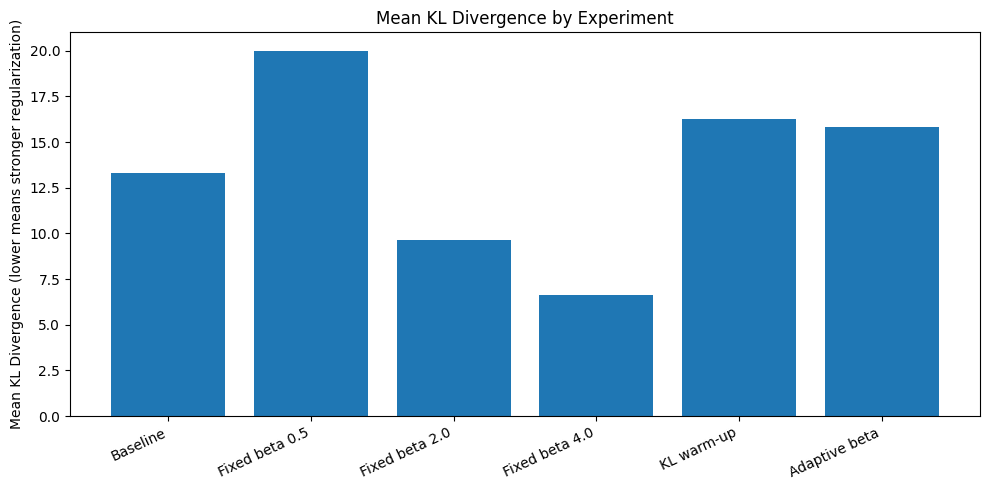

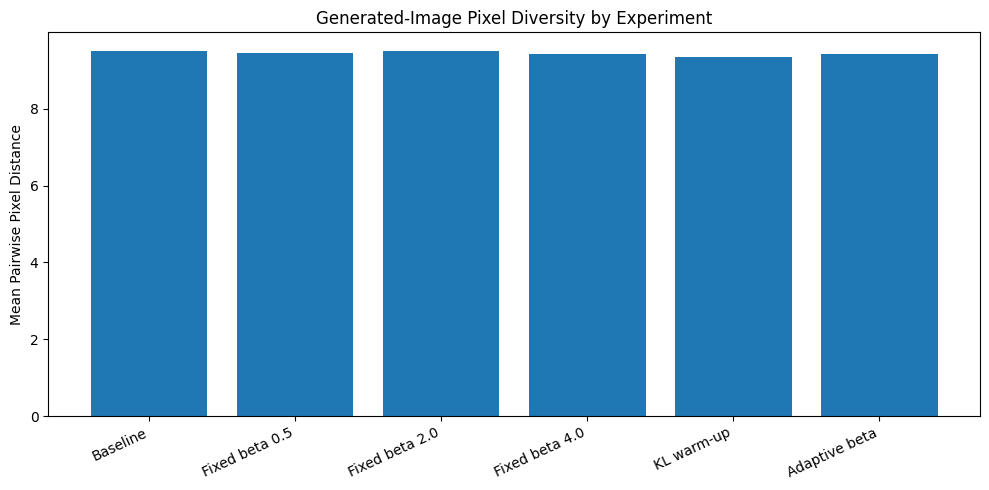

All three graphs saved to: /content/drive/MyDrive/LatentForge/figures


In [ ]:
import matplotlib.pyplot as plt
import os

os.makedirs(FIGURES_DIR, exist_ok=True)

# Graph 1: Reconstruction quality
plt.figure(figsize=(10, 5))
plt.bar(
    latent_df["Experiment"],
    [
        221.2267,
        216.9110,
        225.1748,
        231.1169,
        217.0878,
        217.2489
    ]
)
plt.title("Validation Reconstruction Loss by Experiment")
plt.ylabel("Reconstruction Loss (lower is better)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(
    os.path.join(FIGURES_DIR, "reconstruction_comparison.png"),
    dpi=300
)
plt.show()

# Graph 2: KL divergence
plt.figure(figsize=(10, 5))
plt.bar(
    latent_df["Experiment"],
    [
        13.3148,
        20.0060,
        9.6284,
        6.6013,
        16.2400,
        15.8316
    ]
)
plt.title("Mean KL Divergence by Experiment")
plt.ylabel("Mean KL Divergence (lower means stronger regularization)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(
    os.path.join(FIGURES_DIR, "kl_comparison.png"),
    dpi=300
)
plt.show()

# Graph 3: Generated-image diversity
plt.figure(figsize=(10, 5))
plt.bar(
    diversity_df["Experiment"],
    diversity_df["Mean pairwise distance"]
)
plt.title("Generated-Image Pixel Diversity by Experiment")
plt.ylabel("Mean Pairwise Pixel Distance")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(
    os.path.join(FIGURES_DIR, "diversity_comparison.png"),
    dpi=300
)
plt.show()

print("All three graphs saved to:", FIGURES_DIR)

In [ ]:
import os
import json

history_files = [
    "baseline_history.json",
    "fixed_beta_0_5_history.json",
    "fixed_beta_2_0_history.json",
    "fixed_beta_4_0_history.json",
    "kl_warmup_history.json",
    "adaptive_beta_history.json"
]

for filename in history_files:
    path = os.path.join(RESULTS_DIR, filename)

    print(f"\n{'=' * 55}")
    print(filename)

    if os.path.exists(path):
        with open(path, "r") as f:
            history = json.load(f)

        print("History type:", type(history).__name__)

        if isinstance(history, list):
            print("Number of recorded entries:", len(history))
            if history:
                print("First entry:", history[0])
                print("Last entry:", history[-1])
        elif isinstance(history, dict):
            print(json.dumps(history, indent=2)[:1500])
    else:
        print("File not found.")


baseline_history.json
History type: list
Number of recorded entries: 30
First entry: {'epoch': 1, 'beta': 1.0, 'train_loss': 253.73580467393663, 'train_reconstruction': 241.4550427065249, 'train_kl': 12.28076209061234, 'val_loss': 248.26003206380207, 'val_reconstruction': 235.8046375732422, 'val_kl': 12.455394198099771}
Last entry: {'epoch': 30, 'beta': 1.0, 'train_loss': 236.6881409053096, 'train_reconstruction': 222.9983419958044, 'train_kl': 13.689799034966363, 'val_loss': 234.71177115885416, 'val_reconstruction': 220.96261775716147, 'val_kl': 13.749153732299805}

fixed_beta_0_5_history.json
History type: list
Number of recorded entries: 30
First entry: {'epoch': 1, 'beta': 0.5, 'train_loss': 292.4371951000072, 'train_reconstruction': 284.7263265832972, 'train_kl': 15.421736472235786, 'val_loss': 249.8679493408203, 'val_reconstruction': 240.43530074055988, 'val_kl': 18.865295196533204}
Last entry: {'epoch': 30, 'beta': 0.5, 'train_loss': 227.55133468514902, 'train_reconstruction': 

In [ ]:
import os
import json
import pandas as pd

history_path = os.path.join(
    RESULTS_DIR,
    "adaptive_beta_history.json"
)

with open(history_path, "r") as f:
    adaptive_history = json.load(f)

adaptive_df = pd.DataFrame(adaptive_history)

print("Adaptive beta values by epoch:")
print(
    adaptive_df[["epoch", "beta", "val_reconstruction", "val_kl"]]
    .to_string(index=False)
)

print("\nUnique beta values:")
print(sorted(adaptive_df["beta"].unique()))

Adaptive beta values by epoch:
 epoch  beta  val_reconstruction    val_kl
     1  0.19          237.513110 29.026300
     2  0.28          228.645204 25.916258
     3  0.37          225.322717 22.899198
     4  0.46          223.346070 21.529603
     5  0.55          222.057644 20.241112
     6  0.64          221.453470 19.253771
     7  0.73          220.538463 18.347788
     8  0.82          220.296627 17.285648
     9  0.91          220.054836 16.736618
    10  1.00          220.003606 16.229525
    11  1.00          219.732114 16.140401
    12  1.00          220.175353 16.364011
    13  1.00          219.215688 15.568522
    14  1.00          219.110473 16.179680
    15  1.00          219.224909 15.838978
    16  1.00          218.958041 15.835548
    17  1.00          218.565012 16.065871
    18  1.00          218.415161 16.248055
    19  1.00          218.537152 16.410383
    20  1.00          218.378719 15.665198
    21  1.00          218.223412 16.009861
    22  1.00          2

In [ ]:
import os
import pandas as pd

final_results = pd.DataFrame([
    {
        "Experiment": "Baseline",
        "Beta": 1.0,
        "Validation Reconstruction": 221.2267,
        "Mean KL Divergence": 13.3148,
        "Mean Pairwise Distance": 9.5188
    },
    {
        "Experiment": "Fixed beta 0.5",
        "Beta": 0.5,
        "Validation Reconstruction": 216.9110,
        "Mean KL Divergence": 20.0060,
        "Mean Pairwise Distance": 9.4551
    },
    {
        "Experiment": "Fixed beta 2.0",
        "Beta": 2.0,
        "Validation Reconstruction": 225.1748,
        "Mean KL Divergence": 9.6284,
        "Mean Pairwise Distance": 9.5132
    },
    {
        "Experiment": "Fixed beta 4.0",
        "Beta": 4.0,
        "Validation Reconstruction": 231.1169,
        "Mean KL Divergence": 6.6013,
        "Mean Pairwise Distance": 9.4179
    },
    {
        "Experiment": "KL warm-up",
        "Beta": 1.0,
        "Validation Reconstruction": 217.0878,
        "Mean KL Divergence": 16.2400,
        "Mean Pairwise Distance": 9.3421
    },
    {
        "Experiment": "Adaptive beta",
        "Beta": 1.0,
        "Validation Reconstruction": 217.2489,
        "Mean KL Divergence": 15.8316,
        "Mean Pairwise Distance": 9.4397
    }
])

output_path = os.path.join(
    RESULTS_DIR,
    "final_validation_comparison.csv"
)

final_results.to_csv(output_path, index=False)

print(final_results.round(4).to_string(index=False))
print("\nSaved to:", output_path)

    Experiment  Beta  Validation Reconstruction  Mean KL Divergence  Mean Pairwise Distance
      Baseline   1.0                   221.2267             13.3148                  9.5188
Fixed beta 0.5   0.5                   216.9110             20.0060                  9.4551
Fixed beta 2.0   2.0                   225.1748              9.6284                  9.5132
Fixed beta 4.0   4.0                   231.1169              6.6013                  9.4179
    KL warm-up   1.0                   217.0878             16.2400                  9.3421
 Adaptive beta   1.0                   217.2489             15.8316                  9.4397

Saved to: /content/drive/MyDrive/LatentForge/results/final_validation_comparison.csv


In [ ]:
import os
import json
import torch

# 1. Inspect the existing baseline test results
test_path = os.path.join(
    RESULTS_DIR,
    "baseline_test_results.json"
)

with open(test_path, "r") as f:
    baseline_test = json.load(f)

print("EXISTING BASELINE TEST RESULTS")
print(json.dumps(baseline_test, indent=4))


# 2. Inspect the checkpoint metadata
print("\nCHECKPOINT METADATA")

for name, metadata in checkpoint_metadata.items():
    print(f"\n{name}:")
    print(metadata)

EXISTING BASELINE TEST RESULTS
{
    "experiment": "baseline_vae",
    "beta": 1.0,
    "checkpoint_epoch": 27,
    "test_loss": 235.3117708984375,
    "test_reconstruction": 222.07158125,
    "test_kl": 13.240189115905762
}

CHECKPOINT METADATA

Baseline:
{'epoch': 27, 'beta': 1.0, 'val_loss': 234.54154060872395}

Fixed beta 0.5:
{'epoch': 29, 'beta': 0.5, 'val_loss': 226.91403031412761}

Fixed beta 2.0:
{'epoch': 26, 'beta': 2.0, 'val_loss': 244.43153173828125}

Fixed beta 4.0:
{'epoch': 29, 'beta': 4.0, 'val_loss': 257.522091389974}

KL warm-up:
{'epoch': 3, 'beta': 0.3, 'val_loss': 232.37038887532552}

Adaptive beta:
{'epoch': 29, 'beta': 1.0, 'val_loss': 233.0805020751953}


In [ ]:
import os
import torch

warmup_path = os.path.join(
    CHECKPOINT_DIR,
    "kl_warmup_best.pt"
)

snapshot_path = os.path.join(
    CHECKPOINT_DIR,
    "kl_warmup_runtime_snapshot.pt"
)

print("Saved best-checkpoint metadata:")
print(checkpoint_metadata["KL warm-up"])

print("\nWarm-up checkpoint files:")
print("Original checkpoint exists:", os.path.exists(warmup_path))
print("Runtime snapshot exists:", os.path.exists(snapshot_path))

print("\nCurrent comparison model:")
print("Is runtime model:", loaded_models["KL warm-up"] is warmup_model)

warmup_model.eval()
warmup_metrics = evaluate(warmup_model, val_loader, beta=1.0)

print("\nCurrent warm-up model validation metrics:")
print(warmup_metrics)

Saved best-checkpoint metadata:
{'epoch': 3, 'beta': 0.3, 'val_loss': 232.37038887532552}

Warm-up checkpoint files:
Original checkpoint exists: True
Runtime snapshot exists: True

Current comparison model:
Is runtime model: True


TypeError: evaluate() missing 1 required positional argument: 'device'

In [ ]:

warmup_model.eval()

warmup_metrics = evaluate(
    warmup_model,
    val_loader,
    device,
    beta=1.0
)

print("KL Warm-up — Runtime Model Validation Metrics:")
print(warmup_metrics)



TypeError: evaluate() got multiple values for argument 'beta'

In [ ]:

import inspect

print(inspect.signature(evaluate))



(model, data_loader, beta, device)


In [ ]:

warmup_model.eval()

warmup_metrics = evaluate(
    warmup_model,
    val_loader,
    1.0,
    device
)

print("KL Warm-up — Runtime Model Validation Metrics:")
print(warmup_metrics)



KL Warm-up — Runtime Model Validation Metrics:
{'loss': 233.3277989501953, 'reconstruction': 217.08774963378906, 'kl': 16.240049138387043}


In [ ]:

import pandas as pd

latent_results = []

for name, model in loaded_models.items():
    model.eval()

    metrics = measure_latent_space(model, val_loader)

    latent_results.append({
        "Experiment": name,
        **metrics
    })

latent_df = pd.DataFrame(latent_results)

display(latent_df)

output_path = os.path.join(
    RESULTS_DIR,
    "final_latent_space_comparison.csv"
)

latent_df.to_csv(output_path, index=False)

print(f"\nSaved latent-space comparison to: {output_path}")



,Experiment,Mean KL per image,Aggregate latent mean,Latent mean std,Mean posterior variance
0,Baseline,13.314830,0.002009,0.675594,0.542149
1,Fixed beta 0.5,20.005996,0.003691,0.777661,0.389897
2,Fixed beta 2.0,9.628361,-0.002173,0.592196,0.652467
3,Fixed beta 4.0,6.601304,0.003615,0.527017,0.714818
4,KL warm-up,16.240049,0.017284,0.820785,0.335160
5,Adaptive beta,15.831608,-0.015897,0.802921,0.368281



Saved latent-space comparison to: /content/drive/MyDrive/LatentForge/results/final_latent_space_comparison.csv


In [ ]:

import os
import torch

print("LATENTFORGE — CHECKPOINT CONSISTENCY CHECK\n")

for name, model in loaded_models.items():
    print(f"\nExperiment: {name}")
    print(f"Model type: {type(model).__name__}")
    print(f"Device: {next(model.parameters()).device}")

    if name in checkpoint_metadata:
        print(f"Saved checkpoint metadata: {checkpoint_metadata[name]}")

    if name == "KL warm-up":
        print("Uses runtime warm-up model:",
              model is warmup_model)

print("\nSaved checkpoint files:")

for filename in sorted(os.listdir(CHECKPOINT_DIR)):
    if filename.endswith(".pt"):
        path = os.path.join(CHECKPOINT_DIR, filename)
        print(f"{filename}: {os.path.getsize(path):,} bytes")



LATENTFORGE — CHECKPOINT CONSISTENCY CHECK


Experiment: Baseline
Model type: VAE
Device: cuda:0
Saved checkpoint metadata: {'epoch': 27, 'beta': 1.0, 'val_loss': 234.54154060872395}

Experiment: Fixed beta 0.5
Model type: VAE
Device: cuda:0
Saved checkpoint metadata: {'epoch': 29, 'beta': 0.5, 'val_loss': 226.91403031412761}

Experiment: Fixed beta 2.0
Model type: VAE
Device: cuda:0
Saved checkpoint metadata: {'epoch': 26, 'beta': 2.0, 'val_loss': 244.43153173828125}

Experiment: Fixed beta 4.0
Model type: VAE
Device: cuda:0
Saved checkpoint metadata: {'epoch': 29, 'beta': 4.0, 'val_loss': 257.522091389974}

Experiment: KL warm-up
Model type: VAE
Device: cuda:0
Saved checkpoint metadata: {'epoch': 3, 'beta': 0.3, 'val_loss': 232.37038887532552}
Uses runtime warm-up model: True

Experiment: Adaptive beta
Model type: VAE
Device: cuda:0
Saved checkpoint metadata: {'epoch': 29, 'beta': 1.0, 'val_loss': 233.0805020751953}

Saved checkpoint files:
adaptive_beta_best.pt: 19,933,093 bytes
bas

In [ ]:

import os
import torch

checkpoint_files = {
    "Baseline": "baseline_best.pt",
    "Fixed beta 0.5": "fixed_beta_0_5_best.pt",
    "Fixed beta 2.0": "fixed_beta_2_0_best.pt",
    "Fixed beta 4.0": "fixed_beta_4_0_best.pt",
    "Adaptive beta": "adaptive_beta_best.pt",
}

print("MODEL WEIGHT VERIFICATION\n")

for name, filename in checkpoint_files.items():
    path = os.path.join(CHECKPOINT_DIR, filename)
    saved = torch.load(path, map_location="cpu", weights_only=False)

    # Support either a raw state_dict or a checkpoint dictionary.
    if isinstance(saved, dict) and "model_state_dict" in saved:
        saved_state = saved["model_state_dict"]
    elif isinstance(saved, dict) and "state_dict" in saved:
        saved_state = saved["state_dict"]
    else:
        saved_state = saved

    current_state = loaded_models[name].state_dict()

    if set(saved_state.keys()) != set(current_state.keys()):
        print(f"{name}: State-dict keys do not match")
        continue

    matches = all(
        torch.equal(
            current_state[key].detach().cpu(),
            saved_state[key].detach().cpu()
        )
        for key in current_state
    )

    print(f"{name}: Current model exactly matches saved checkpoint = {matches}")

# Check the warm-up snapshot separately.
snapshot_path = os.path.join(
    CHECKPOINT_DIR,
    "kl_warmup_runtime_snapshot.pt"
)

snapshot = torch.load(
    snapshot_path,
    map_location="cpu",
    weights_only=False
)

if isinstance(snapshot, dict) and "model_state_dict" in snapshot:
    snapshot_state = snapshot["model_state_dict"]
elif isinstance(snapshot, dict) and "state_dict" in snapshot:
    snapshot_state = snapshot["state_dict"]
else:
    snapshot_state = snapshot

warmup_current = loaded_models["KL warm-up"].state_dict()

if set(snapshot_state.keys()) == set(warmup_current.keys()):
    warmup_matches = all(
        torch.equal(
            warmup_current[key].detach().cpu(),
            snapshot_state[key].detach().cpu()
        )
        for key in warmup_current
    )
    print(
        "KL warm-up: Runtime model exactly matches saved snapshot =",
        warmup_matches
    )
else:
    print("KL warm-up: Snapshot keys do not match current model keys")



MODEL WEIGHT VERIFICATION

Baseline: Current model exactly matches saved checkpoint = True
Fixed beta 0.5: Current model exactly matches saved checkpoint = True
Fixed beta 2.0: Current model exactly matches saved checkpoint = True
Fixed beta 4.0: Current model exactly matches saved checkpoint = True
Adaptive beta: Current model exactly matches saved checkpoint = True
KL warm-up: Runtime model exactly matches saved snapshot = True


In [ ]:

import pandas as pd
import os

final_validation_results = []

final_betas = {
    "Baseline": 1.0,
    "Fixed beta 0.5": 0.5,
    "Fixed beta 2.0": 2.0,
    "Fixed beta 4.0": 4.0,
    "KL warm-up": 1.0,
    "Adaptive beta": 1.0,
}

for name, model in loaded_models.items():
    beta = final_betas[name]
    model.eval()

    metrics = evaluate(model, val_loader, beta, device)

    final_validation_results.append({
        "Experiment": name,
        "Beta": beta,
        "Validation Loss": metrics["loss"],
        "Reconstruction Loss": metrics["reconstruction"],
        "Mean KL Divergence": metrics["kl"],
    })

final_validation_df = pd.DataFrame(final_validation_results)

display(final_validation_df.round(4))

output_path = os.path.join(
    RESULTS_DIR,
    "final_validation_comparison_verified.csv"
)

final_validation_df.to_csv(output_path, index=False)

print(f"\nSaved verified validation results to: {output_path}")



,Experiment,Beta,Validation Loss,Reconstruction Loss,Mean KL Divergence
0,Baseline,1.0,234.5415,221.2267,13.3148
1,Fixed beta 0.5,0.5,226.9140,216.9110,20.0060
2,Fixed beta 2.0,2.0,244.4315,225.1748,9.6284
3,Fixed beta 4.0,4.0,257.5221,231.1169,6.6013
4,KL warm-up,1.0,233.3278,217.0877,16.2400
5,Adaptive beta,1.0,233.0805,217.2489,15.8316



Saved verified validation results to: /content/drive/MyDrive/LatentForge/results/final_validation_comparison_verified.csv


In [ ]:
import os

print("LATENTFORGE SAVE CHECK\n")

for folder in ["results", "checkpoints", "figures"]:
    path = os.path.join(PROJECT_DIR, folder)
    print(f"\n{folder.upper()}:")

    if os.path.isdir(path):
        for filename in sorted(os.listdir(path)):
            print("  ✅", filename)
    else:
        print("  ❌ Folder not found")

print("\nNotebook code: Make sure your latest cells are saved.")

LATENTFORGE SAVE CHECK


RESULTS:
  ✅ adaptive_beta_history.json
  ✅ baseline_history.json
  ✅ baseline_history_backup_before_cleanup.json
  ✅ baseline_test_results.json
  ✅ final_latent_space_comparison.csv
  ✅ final_validation_comparison.csv
  ✅ final_validation_comparison_verified.csv
  ✅ fixed_beta_0_5_history.json
  ✅ fixed_beta_2_0_history.json
  ✅ fixed_beta_4_0_history.json
  ✅ kl_warmup_history.json

CHECKPOINTS:
  ✅ adaptive_beta_best.pt
  ✅ baseline_best.pt
  ✅ fixed_beta_0_5_best.pt
  ✅ fixed_beta_2_0_best.pt
  ✅ fixed_beta_4_0_best.pt
  ✅ kl_warmup_best.pt
  ✅ kl_warmup_runtime_snapshot.pt

FIGURES:
  ✅ baseline_generated_samples.png
  ✅ baseline_reconstructions.png
  ✅ diversity_comparison.png
  ✅ fashion_mnist_samples.png
  ✅ generated_samples_comparison.png
  ✅ kl_comparison.png
  ✅ reconstruction_comparison.png

Notebook code: Make sure your latest cells are saved.


In [ ]:
print("Runtime is active!")
print("PyTorch available:", torch.cuda.is_available())
print("Device:", device)

Runtime is active!


NameError: name 'torch' is not defined

In [ ]:

import os
from google.colab import drive

# Step 1: Mount Google Drive
drive.mount('/content/drive')

# Step 2: Set project path
PROJECT_DIR = "/content/drive/MyDrive/LatentForge"

print("\n" + "=" * 55)
print("       LATENTFORGE PROJECT FILE VERIFICATION")
print("=" * 55)

if not os.path.exists(PROJECT_DIR):
    print("\nERROR: LatentForge project folder was not found.")
    print("Please check the folder name and Google Drive location.")
else:
    print("\nProject folder found:", PROJECT_DIR)

    folders = {
        "checkpoints": [
            "baseline_best.pt",
            "fixed_beta_0_5_best.pt",
            "fixed_beta_2_0_best.pt",
            "fixed_beta_4_0_best.pt",
            "kl_warmup_best.pt",
            "adaptive_beta_best.pt",
            "kl_warmup_runtime_snapshot.pt"
        ],
        "results": [
            "final_validation_comparison_verified.csv",
            "final_latent_space_comparison.csv",
            "baseline_test_results.json",
            "baseline_history.json",
            "fixed_beta_0_5_history.json",
            "fixed_beta_2_0_history.json",
            "fixed_beta_4_0_history.json",
            "kl_warmup_history.json",
            "adaptive_beta_history.json"
        ],
        "figures": [
            "baseline_generated_samples.png",
            "baseline_reconstructions.png",
            "diversity_comparison.png",
            "fashion_mnist_samples.png",
            "generated_samples_comparison.png",
            "kl_comparison.png",
            "reconstruction_comparison.png"
        ]
    }

    total = 0
    found = 0

    for folder, expected_files in folders.items():
        folder_path = os.path.join(PROJECT_DIR, folder)

        print(f"\n{'-' * 45}")
        print(f"FOLDER: {folder}")
        print("-" * 45)

        if not os.path.isdir(folder_path):
            print("FOLDER NOT FOUND")
            total += len(expected_files)
            continue

        for filename in expected_files:
            total += 1
            filepath = os.path.join(folder_path, filename)

            if os.path.isfile(filepath):
                size_mb = os.path.getsize(filepath) / (1024 * 1024)
                print(f"[FOUND]   {filename} ({size_mb:.2f} MB)")
                found += 1
            else:
                print(f"[MISSING] {filename}")

    print("\n" + "=" * 55)
    print(f"FILES FOUND: {found}/{total}")
    print("=" * 55)

    if found == total:
        print("All expected files were found.")
    else:
        print("Some files are missing; check the output above.")

    print("\nNo models were trained or files modified.")


Mounted at /content/drive

       LATENTFORGE PROJECT FILE VERIFICATION

Project folder found: /content/drive/MyDrive/LatentForge

---------------------------------------------
FOLDER: checkpoints
---------------------------------------------
[FOUND]   baseline_best.pt (19.01 MB)
[FOUND]   fixed_beta_0_5_best.pt (19.01 MB)
[FOUND]   fixed_beta_2_0_best.pt (19.01 MB)
[FOUND]   fixed_beta_4_0_best.pt (19.01 MB)
[FOUND]   kl_warmup_best.pt (19.01 MB)
[FOUND]   adaptive_beta_best.pt (19.01 MB)
[FOUND]   kl_warmup_runtime_snapshot.pt (6.34 MB)

---------------------------------------------
FOLDER: results
---------------------------------------------
[FOUND]   final_validation_comparison_verified.csv (0.00 MB)
[FOUND]   final_latent_space_comparison.csv (0.00 MB)
[FOUND]   baseline_test_results.json (0.00 MB)
[FOUND]   baseline_history.json (0.01 MB)
[FOUND]   fixed_beta_0_5_history.json (0.01 MB)
[FOUND]   fixed_beta_2_0_history.json (0.01 MB)
[FOUND]   fixed_beta_4_0_history.json (0.01 MB

In [ ]:

import os
import torch

PROJECT_DIR = "/content/drive/MyDrive/LatentForge"
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")

checkpoint_path = os.path.join(
    CHECKPOINT_DIR, "baseline_best.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

# Handle either a raw state_dict or a wrapped checkpoint
if "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
elif "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
else:
    state_dict = checkpoint

print("=" * 60)
print("LATENTFORGE — ORIGINAL VAE ARCHITECTURE")
print("=" * 60)

for name, tensor in state_dict.items():
    if isinstance(tensor, torch.Tensor):
        print(f"{name:35s} {tuple(tensor.shape)}")



LATENTFORGE — ORIGINAL VAE ARCHITECTURE
encoder.0.weight                    (32, 1, 3, 3)
encoder.0.bias                      (32,)
encoder.2.weight                    (64, 32, 3, 3)
encoder.2.bias                      (64,)
encoder.5.weight                    (256, 3136)
encoder.5.bias                      (256,)
fc_mu.weight                        (16, 256)
fc_mu.bias                          (16,)
fc_logvar.weight                    (16, 256)
fc_logvar.bias                      (16,)
decoder_input.0.weight              (256, 16)
decoder_input.0.bias                (256,)
decoder_input.2.weight              (3136, 256)
decoder_input.2.bias                (3136,)
decoder.1.weight                    (64, 32, 3, 3)
decoder.1.bias                      (32,)
decoder.3.weight                    (32, 1, 3, 3)
decoder.3.bias                      (1,)


In [ ]:

import os
import torch
import torch.nn as nn

PROJECT_DIR = "/content/drive/MyDrive/LatentForge"
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


# Reconstructed architecture matching the checkpoint parameter shapes
class VAE(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 256)
        )

        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)

        self.decoder_input = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 64 * 7 * 7),
            nn.ReLU()
        )

        self.decoder = nn.Sequential(
            nn.Unflatten(1, (64, 7, 7)),
            nn.ConvTranspose2d(
                64, 32, kernel_size=3, stride=2,
                padding=1, output_padding=1
            ),
            nn.ReLU(),
            nn.ConvTranspose2d(
                32, 1, kernel_size=3, stride=2,
                padding=1, output_padding=1
            ),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.decoder(self.decoder_input(z))

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstruction = self.decode(z)
        return reconstruction, mu, logvar


checkpoint_files = {
    "Baseline": "baseline_best.pt",
    "Fixed beta 0.5": "fixed_beta_0_5_best.pt",
    "Fixed beta 2.0": "fixed_beta_2_0_best.pt",
    "Fixed beta 4.0": "fixed_beta_4_0_best.pt",
    "KL warm-up": "kl_warmup_runtime_snapshot.pt",
    "Adaptive beta": "adaptive_beta_best.pt"
}

loaded_models = {}
failed_models = {}

for name, filename in checkpoint_files.items():
    path = os.path.join(CHECKPOINT_DIR, filename)

    try:
        checkpoint = torch.load(
            path, map_location=device, weights_only=True
        )

        if "state_dict" in checkpoint:
            state_dict = checkpoint["state_dict"]
        elif "model_state_dict" in checkpoint:
            state_dict = checkpoint["model_state_dict"]
        else:
            state_dict = checkpoint

        model = VAE(latent_dim=16).to(device)
        model.load_state_dict(state_dict)
        model.eval()

        loaded_models[name] = model
        print(f"✅ {name}: loaded successfully")

    except Exception as e:
        failed_models[name] = str(e)
        print(f"❌ {name}: {e}")

print("\n" + "=" * 45)
print(f"Models loaded: {len(loaded_models)}/{len(checkpoint_files)}")
print("=" * 45)



Device: cuda
✅ Baseline: loaded successfully
✅ Fixed beta 0.5: loaded successfully
✅ Fixed beta 2.0: loaded successfully
✅ Fixed beta 4.0: loaded successfully
✅ KL warm-up: loaded successfully
✅ Adaptive beta: loaded successfully

Models loaded: 6/6


In [ ]:
import torch

print("LATENTFORGE — MODEL SANITY CHECK")
print("=" * 50)

for name, model in loaded_models.items():
    try:
        model.eval()

        # Synthetic input only; no dataset setup required
        x = torch.rand(4, 1, 28, 28, device=device)

        with torch.no_grad():
            reconstruction, mu, logvar = model(x)

        valid_shape = reconstruction.shape == x.shape
        finite_output = torch.isfinite(reconstruction).all().item()
        valid_range = (
            reconstruction.min().item() >= 0
            and reconstruction.max().item() <= 1
        )

        print(f"\n{name}")
        print("  Input shape:", tuple(x.shape))
        print("  Output shape:", tuple(reconstruction.shape))
        print("  Latent shape:", tuple(mu.shape))
        print("  Output finite:", finite_output)
        print("  Output in [0, 1]:", valid_range)

        if valid_shape and finite_output and valid_range:
            print("  Status: PASS")
        else:
            print("  Status: CHECK REQUIRED")

    except Exception as e:
        print(f"\n{name}: FAILED — {e}")

print("\n" + "=" * 50)

LATENTFORGE — MODEL SANITY CHECK

Baseline
  Input shape: (4, 1, 28, 28)
  Output shape: (4, 1, 28, 28)
  Latent shape: (4, 16)
  Output finite: True
  Output in [0, 1]: True
  Status: PASS

Fixed beta 0.5
  Input shape: (4, 1, 28, 28)
  Output shape: (4, 1, 28, 28)
  Latent shape: (4, 16)
  Output finite: True
  Output in [0, 1]: True
  Status: PASS

Fixed beta 2.0
  Input shape: (4, 1, 28, 28)
  Output shape: (4, 1, 28, 28)
  Latent shape: (4, 16)
  Output finite: True
  Output in [0, 1]: True
  Status: PASS

Fixed beta 4.0
  Input shape: (4, 1, 28, 28)
  Output shape: (4, 1, 28, 28)
  Latent shape: (4, 16)
  Output finite: True
  Output in [0, 1]: True
  Status: PASS

KL warm-up
  Input shape: (4, 1, 28, 28)
  Output shape: (4, 1, 28, 28)
  Latent shape: (4, 16)
  Output finite: True
  Output in [0, 1]: True
  Status: PASS

Adaptive beta
  Input shape: (4, 1, 28, 28)
  Output shape: (4, 1, 28, 28)
  Latent shape: (4, 16)
  Output finite: True
  Output in [0, 1]: True
  Status: PASS


In [ ]:
import os
import pandas as pd

PROJECT_DIR = "/content/drive/MyDrive/LatentForge"
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

csv_path = os.path.join(
    RESULTS_DIR,
    "final_validation_comparison_verified.csv"
)

if os.path.exists(csv_path):
    results_df = pd.read_csv(csv_path)

    print("LATENTFORGE — SAVED VALIDATION RESULTS")
    print("=" * 65)
    print(results_df.to_string(index=False))
    print("\nColumns:", results_df.columns.tolist())
    print("\nRows:", len(results_df))
    print("\nMissing values per column:")
    print(results_df.isnull().sum())
else:
    print("Validation comparison CSV not found:", csv_path)

LATENTFORGE — SAVED VALIDATION RESULTS
    Experiment  Beta  Validation Loss  Reconstruction Loss  Mean KL Divergence
      Baseline   1.0       234.541541           221.226712           13.314830
Fixed beta 0.5   0.5       226.914031           216.911032           20.005996
Fixed beta 2.0   2.0       244.431532           225.174809            9.628361
Fixed beta 4.0   4.0       257.522092           231.116875            6.601304
    KL warm-up   1.0       233.327799           217.087750           16.240049
 Adaptive beta   1.0       233.080502           217.248895           15.831608

Columns: ['Experiment', 'Beta', 'Validation Loss', 'Reconstruction Loss', 'Mean KL Divergence']

Rows: 6

Missing values per column:
Experiment             0
Beta                   0
Validation Loss        0
Reconstruction Loss    0
Mean KL Divergence     0
dtype: int64


In [ ]:
print("evaluate exists:", "evaluate" in globals())
print("val_loader exists:", "val_loader" in globals())
print("train_loader exists:", "train_loader" in globals())

if "val_loader" in globals():
    print("Validation batches:", len(val_loader))

if "evaluate" in globals():
    print("Evaluation function:", evaluate)

evaluate exists: False
val_loader exists: False
train_loader exists: False


In [ ]:
import os

from google.colab import drive
drive.mount('/content/drive')

search_root = "/content/drive/MyDrive"

print("Searching for LatentForge notebooks...\n")

for root, dirs, files in os.walk(search_root):
    # Skip folders that are unlikely to contain the project notebook
    dirs[:] = [
        d for d in dirs
        if d not in {".ipynb_checkpoints", "node_modules", ".git"}
    ]

    for file in files:
        if file.endswith(".ipynb"):
            if "latentforge" in file.lower() or "vae" in file.lower():
                print(os.path.join(root, file))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Searching for LatentForge notebooks...



In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/LatentForge"

print("Project folder exists:", os.path.exists(PROJECT_DIR))

if os.path.exists(PROJECT_DIR):
    for root, dirs, files in os.walk(PROJECT_DIR):
        level = root.replace(PROJECT_DIR, "").count(os.sep)

        if level > 2:
            dirs[:] = []
            continue

        indent = "    " * level
        print(f"{indent}{os.path.basename(root)}/")

        for file in files:
            print(f"{indent}    {file}")
else:
    print("Project folder not found. Checking MyDrive folders...")
    for item in os.listdir("/content/drive/MyDrive"):
        print(item)

Project folder exists: True
LatentForge/
    checkpoints/
        baseline_best.pt
        fixed_beta_0_5_best.pt
        fixed_beta_2_0_best.pt
        fixed_beta_4_0_best.pt
        kl_warmup_best.pt
        adaptive_beta_best.pt
        kl_warmup_runtime_snapshot.pt
    data/
        FashionMNIST/
    results/
        baseline_history_backup_before_cleanup.json
        baseline_history.json
        baseline_test_results.json
        fixed_beta_0_5_history.json
        fixed_beta_2_0_history.json
        fixed_beta_4_0_history.json
        kl_warmup_history.json
        adaptive_beta_history.json
        final_validation_comparison.csv
        final_latent_space_comparison.csv
        final_validation_comparison_verified.csv
    figures/
        fashion_mnist_samples.png
        baseline_reconstructions.png
        baseline_generated_samples.png
        generated_samples_comparison.png
        kl_comparison.png
        diversity_comparison.png
        reconstruction_comparison.png


In [ ]:
import os
import json

PROJECT_DIR = "/content/drive/MyDrive/LatentForge"
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

history_files = [
    "baseline_history.json",
    "fixed_beta_0_5_history.json",
    "fixed_beta_2_0_history.json",
    "fixed_beta_4_0_history.json",
    "kl_warmup_history.json",
    "adaptive_beta_history.json",
]

for filename in history_files:
    path = os.path.join(RESULTS_DIR, filename)

    print("\n" + "=" * 65)
    print(filename)

    with open(path, "r") as f:
        history = json.load(f)

    print("Data type:", type(history).__name__)

    if isinstance(history, dict):
        print("Keys:", list(history.keys()))

        for key, value in history.items():
            if isinstance(value, list):
                print(f"{key}: {len(value)} entries")
                if value:
                    print("First entry:", str(value[0])[:300])
            else:
                print(f"{key}: {str(value)[:200]}")

    elif isinstance(history, list):
        print("Entries:", len(history))
        if history:
            print("First entry:", str(history[0])[:500])
            print("Last entry:", str(history[-1])[:500])


baseline_history.json
Data type: list
Entries: 30
First entry: {'epoch': 1, 'beta': 1.0, 'train_loss': 253.73580467393663, 'train_reconstruction': 241.4550427065249, 'train_kl': 12.28076209061234, 'val_loss': 248.26003206380207, 'val_reconstruction': 235.8046375732422, 'val_kl': 12.455394198099771}
Last entry: {'epoch': 30, 'beta': 1.0, 'train_loss': 236.6881409053096, 'train_reconstruction': 222.9983419958044, 'train_kl': 13.689799034966363, 'val_loss': 234.71177115885416, 'val_reconstruction': 220.96261775716147, 'val_kl': 13.749153732299805}

fixed_beta_0_5_history.json
Data type: list
Entries: 30
First entry: {'epoch': 1, 'beta': 0.5, 'train_loss': 292.4371951000072, 'train_reconstruction': 284.7263265832972, 'train_kl': 15.421736472235786, 'val_loss': 249.8679493408203, 'val_reconstruction': 240.43530074055988, 'val_kl': 18.865295196533204}
Last entry: {'epoch': 30, 'beta': 0.5, 'train_loss': 227.55133468514902, 'train_reconstruction': 217.6118878309462, 'train_kl': 19.8788946550

In [ ]:
import os
import torch

PROJECT_DIR = "/content/drive/MyDrive/LatentForge"
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")

checkpoint_files = [
    "baseline_best.pt",
    "fixed_beta_0_5_best.pt",
    "fixed_beta_2_0_best.pt",
    "fixed_beta_4_0_best.pt",
    "kl_warmup_best.pt",
    "adaptive_beta_best.pt",
    "kl_warmup_runtime_snapshot.pt",
]

for filename in checkpoint_files:
    path = os.path.join(CHECKPOINT_DIR, filename)

    print("\n" + "=" * 60)
    print(filename)

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    if isinstance(checkpoint, dict):
        print("Top-level keys:", list(checkpoint.keys()))

        for key, value in checkpoint.items():
            if key not in ("model_state_dict", "state_dict"):
                if isinstance(value, dict):
                    print(f"{key}: keys = {list(value.keys())}")
                elif isinstance(value, torch.Tensor):
                    print(f"{key}: tensor shape = {tuple(value.shape)}")
                else:
                    print(f"{key}: {str(value)[:250]}")
    else:
        print("Checkpoint type:", type(checkpoint).__name__)


baseline_best.pt
Top-level keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'beta', 'val_loss', 'seed', 'latent_dim']
epoch: 27
optimizer_state_dict: keys = ['state', 'param_groups']
beta: 1.0
val_loss: 234.54154060872395
seed: 42
latent_dim: 16

fixed_beta_0_5_best.pt
Top-level keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'beta', 'val_loss', 'seed', 'latent_dim']
epoch: 29
optimizer_state_dict: keys = ['state', 'param_groups']
beta: 0.5
val_loss: 226.91403031412761
seed: 42
latent_dim: 16

fixed_beta_2_0_best.pt
Top-level keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'beta', 'val_loss', 'seed', 'latent_dim']
epoch: 26
optimizer_state_dict: keys = ['state', 'param_groups']
beta: 2.0
val_loss: 244.43153173828125
seed: 42
latent_dim: 16

fixed_beta_4_0_best.pt
Top-level keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'beta', 'val_loss', 'seed', 'latent_dim']
epoch: 29
optimizer_state_dict: keys = ['state', 'param_groups']
beta: 4.0
val

In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/LatentForge"

print("Items inside LatentForge:\n")

for item in os.listdir(PROJECT_DIR):
    path = os.path.join(PROJECT_DIR, item)
    if os.path.isdir(path):
        print(f"📁 {item}/")
    else:
        print(f"📄 {item}")

Items inside LatentForge:

📁 checkpoints/
📁 data/
📁 results/
📁 figures/


In [ ]:
import os

path = "/content/drive/MyDrive/LatentForge"

print("Exists:", os.path.exists(path))
print("Is folder:", os.path.isdir(path))
print("Is file:", os.path.isfile(path))

if os.path.isdir(path):
    print("\nContents:")
    print(os.listdir(path))

Exists: True
Is folder: True
Is file: False

Contents:
['checkpoints', 'data', 'results', 'figures']


In [ ]:
import json

notebook_path = "/content/drive/MyDrive/Colab Notebooks/LatentForge.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

for i in range(69, min(82, len(notebook["cells"]))):
    cell = notebook["cells"][i]
    print(f"\n{'=' * 25} CELL {i} {'=' * 25}")
    print("Type:", cell["cell_type"])

    if cell["cell_type"] == "code":
        print("".join(cell.get("source", [])))

        outputs = cell.get("outputs", [])
        for output in outputs:
            if "text" in output:
                print("SAVED OUTPUT:")
                print("".join(output["text"]))
            elif "ename" in output:
                print("SAVED ERROR:", output["ename"])
                print(output.get("evalue", ""))
    else:
        print("".join(cell.get("source", [])))


========================= CELL 69 =========================
Type: code

import pandas as pd
import os

final_validation_results = []

final_betas = {
    "Baseline": 1.0,
    "Fixed beta 0.5": 0.5,
    "Fixed beta 2.0": 2.0,
    "Fixed beta 4.0": 4.0,
    "KL warm-up": 1.0,
    "Adaptive beta": 1.0,
}

for name, model in loaded_models.items():
    beta = final_betas[name]
    model.eval()

    metrics = evaluate(model, val_loader, beta, device)

    final_validation_results.append({
        "Experiment": name,
        "Beta": beta,
        "Validation Loss": metrics["loss"],
        "Reconstruction Loss": metrics["reconstruction"],
        "Mean KL Divergence": metrics["kl"],
    })

final_validation_df = pd.DataFrame(final_validation_results)

display(final_validation_df.round(4))

output_path = os.path.join(
    RESULTS_DIR,
    "final_validation_comparison_verified.csv"
)

final_validation_df.to_csv(output_path, index=False)

print(f"\nSaved verified validation results to: {output_

In [ ]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

PROJECT_DIR = "/content/drive/MyDrive/LatentForge"
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
DATA_DIR = os.path.join(PROJECT_DIR, "data")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
LATENT_DIM = 16
BATCH_SIZE = 128

# Restore the ORIGINAL architecture from notebook Cell 4
class VAE(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__()
        self.latent_dim = latent_dim

        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, 3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, 3, stride=2, padding=1),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 256),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)

        self.decoder_input = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 64 * 7 * 7),
            nn.ReLU()
        )

        self.decoder = nn.Sequential(
            nn.Unflatten(1, (64, 7, 7)),
            nn.ConvTranspose2d(
                64, 32, 3, stride=2, padding=1, output_padding=1
            ),
            nn.ReLU(),
            nn.ConvTranspose2d(
                32, 1, 3, stride=2, padding=1, output_padding=1
            ),
            nn.Sigmoid()
        )

    def encode(self, x):
        features = self.encoder(x)
        return self.fc_mu(features), self.fc_logvar(features)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        return mu + torch.randn_like(std) * std

    def decode(self, z):
        return self.decoder(self.decoder_input(z))

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar


# Restore the original loss convention.
# Verify this against the notebook's vae_loss function before evaluation.
def vae_loss(reconstructions, images, mu, logvar, beta=1.0):
    reconstruction_loss = F.binary_cross_entropy(
        reconstructions, images, reduction="none"
    ).flatten(1).sum(dim=1).mean()

    kl_loss = -0.5 * (
        1 + logvar - mu.pow(2) - logvar.exp()
    ).sum(dim=1).mean()

    total_loss = reconstruction_loss + beta * kl_loss

    return total_loss, reconstruction_loss, kl_loss


@torch.no_grad()
def evaluate(model, data_loader, beta, device):
    model.eval()
    total_loss = reconstruction_sum = kl_sum = 0.0
    total_images = 0

    for images, _ in data_loader:
        images = images.to(device, non_blocking=True)
        mu, logvar = model.encode(images)
        reconstructions = model.decode(mu)

        loss, recon_loss, kl_loss = vae_loss(
            reconstructions, images, mu, logvar, beta
        )

        n = images.size(0)
        total_loss += loss.item() * n
        reconstruction_sum += recon_loss.item() * n
        kl_sum += kl_loss.item() * n
        total_images += n

    if total_images == 0:
        raise ValueError("Evaluation data loader is empty.")

    return {
        "loss": total_loss / total_images,
        "reconstruction": reconstruction_sum / total_images,
        "kl": kl_sum / total_images
    }


print("Device:", device)
print("Original VAE architecture restored.")
print("Evaluation function restored.")
print("No training performed.")

Device: cuda
Original VAE architecture restored.
Evaluation function restored.
No training performed.


In [ ]:
import torch
import torch.nn.functional as F

def vae_loss(reconstructions, images, mu, logvar, beta=1.0):

    reconstruction_loss = F.binary_cross_entropy(
        reconstructions,
        images,
        reduction="sum"
    ) / images.size(0)

    kl_per_image = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp(),
        dim=1
    )

    kl_loss = kl_per_image.mean()

    total_loss = reconstruction_loss + beta * kl_loss

    return total_loss, reconstruction_loss, kl_loss


print("Original VAE loss function restored.")

Original VAE loss function restored.


In [ ]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

SEED = 42
BATCH_SIZE = 128

transform = transforms.ToTensor()

train_dataset = datasets.FashionMNIST(
    root=DATA_DIR,
    train=True,
    download=False,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root=DATA_DIR,
    train=False,
    download=False,
    transform=transform
)

train_data, val_data = random_split(
    train_dataset,
    [54000, 6000],
    generator=torch.Generator().manual_seed(SEED)
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Test images:", len(test_dataset))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

images, labels = next(iter(val_loader))
print("Validation batch shape:", images.shape)
print("Pixel range:", images.min().item(), "to", images.max().item())

assert len(train_data) == 54000
assert len(val_data) == 6000
assert len(test_dataset) == 10000
assert images.shape[1:] == (1, 28, 28)

print("Dataset restoration successful.")

Training images: 54000
Validation images: 6000
Test images: 10000
Validation batches: 47
Test batches: 79
Validation batch shape: torch.Size([128, 1, 28, 28])
Pixel range: 0.0 to 1.0
Dataset restoration successful.


In [ ]:
import os
import torch

checkpoint_files = {
    "Baseline": "baseline_best.pt",
    "Fixed beta 0.5": "fixed_beta_0_5_best.pt",
    "Fixed beta 2.0": "fixed_beta_2_0_best.pt",
    "Fixed beta 4.0": "fixed_beta_4_0_best.pt",
    "KL warm-up": "kl_warmup_best.pt",
    "Adaptive beta": "adaptive_beta_best.pt"
}

loaded_models = {}
checkpoint_info = {}

for name, filename in checkpoint_files.items():
    path = os.path.join(CHECKPOINT_DIR, filename)

    checkpoint = torch.load(
        path,
        map_location=device,
        weights_only=True
    )

    state_dict = checkpoint.get(
        "model_state_dict",
        checkpoint.get("state_dict", checkpoint)
    )

    model = VAE(latent_dim=LATENT_DIM).to(device)
    model.load_state_dict(state_dict)
    model.eval()

    loaded_models[name] = model

    checkpoint_info[name] = {
        "file": filename,
        "epoch": checkpoint.get("epoch", "unknown"),
        "beta": checkpoint.get("beta", "unknown"),
        "val_loss": checkpoint.get("val_loss", "unknown")
    }

    print(f"Loaded: {name}")

print("\nCheckpoint metadata:")
for name, info in checkpoint_info.items():
    print(name, "->", info)

print("\nModels loaded:", len(loaded_models))

Loaded: Baseline
Loaded: Fixed beta 0.5
Loaded: Fixed beta 2.0
Loaded: Fixed beta 4.0
Loaded: KL warm-up
Loaded: Adaptive beta

Checkpoint metadata:
Baseline -> {'file': 'baseline_best.pt', 'epoch': 27, 'beta': 1.0, 'val_loss': 234.54154060872395}
Fixed beta 0.5 -> {'file': 'fixed_beta_0_5_best.pt', 'epoch': 29, 'beta': 0.5, 'val_loss': 226.91403031412761}
Fixed beta 2.0 -> {'file': 'fixed_beta_2_0_best.pt', 'epoch': 26, 'beta': 2.0, 'val_loss': 244.43153173828125}
Fixed beta 4.0 -> {'file': 'fixed_beta_4_0_best.pt', 'epoch': 29, 'beta': 4.0, 'val_loss': 257.522091389974}
KL warm-up -> {'file': 'kl_warmup_best.pt', 'epoch': 3, 'beta': 0.3, 'val_loss': 232.37038887532552}
Adaptive beta -> {'file': 'adaptive_beta_best.pt', 'epoch': 29, 'beta': 1.0, 'val_loss': 233.0805020751953}

Models loaded: 6


In [ ]:
import pandas as pd

validation_results = []

for name, model in loaded_models.items():
    beta = checkpoint_info[name]["beta"]

    metrics = evaluate(
        model=model,
        data_loader=val_loader,
        beta=beta,
        device=device
    )

    validation_results.append({
        "Experiment": name,
        "Checkpoint Epoch": checkpoint_info[name]["epoch"],
        "Beta": beta,
        "Validation Loss": metrics["loss"],
        "Reconstruction Loss": metrics["reconstruction"],
        "Mean KL Divergence": metrics["kl"]
    })

    print(
        f"{name}: "
        f"Reconstruction={metrics['reconstruction']:.4f}, "
        f"KL={metrics['kl']:.4f}, "
        f"Total={metrics['loss']:.4f}"
    )

validation_df = pd.DataFrame(validation_results)

print("\nVALIDATION RESULTS")
display(
    validation_df.style.format({
        "Validation Loss": "{:.4f}",
        "Reconstruction Loss": "{:.4f}",
        "Mean KL Divergence": "{:.4f}"
    })
)

Baseline: Reconstruction=221.2267, KL=13.3148, Total=234.5415
Fixed beta 0.5: Reconstruction=216.9110, KL=20.0060, Total=226.9140
Fixed beta 2.0: Reconstruction=225.1748, KL=9.6284, Total=244.4315
Fixed beta 4.0: Reconstruction=231.1169, KL=6.6013, Total=257.5221
KL warm-up: Reconstruction=224.3516, KL=26.7293, Total=232.3704
Adaptive beta: Reconstruction=217.2489, KL=15.8316, Total=233.0805

VALIDATION RESULTS


,Experiment,Checkpoint Epoch,Beta,Validation Loss,Reconstruction Loss,Mean KL Divergence
0,Baseline,27,1.000000,234.5415,221.2267,13.3148
1,Fixed beta 0.5,29,0.500000,226.9140,216.9110,20.0060
2,Fixed beta 2.0,26,2.000000,244.4315,225.1748,9.6284
3,Fixed beta 4.0,29,4.000000,257.5221,231.1169,6.6013
4,KL warm-up,3,0.300000,232.3704,224.3516,26.7293
5,Adaptive beta,29,1.000000,233.0805,217.2489,15.8316


In [ ]:
import json
import os

history_path = os.path.join(
    PROJECT_DIR,
    "results",
    "kl_warmup_history.json"
)

with open(history_path, "r") as f:
    warmup_history_saved = json.load(f)

print("Number of history records:", len(warmup_history_saved))

print("\nFirst 5 records:")
for record in warmup_history_saved[:5]:
    print(record)

print("\nLast 3 records:")
for record in warmup_history_saved[-3:]:
    print(record)

print("\nSaved warm-up checkpoint:")
print(checkpoint_info["KL warm-up"])

Number of history records: 30

First 5 records:
{'epoch': 1, 'beta': 0.1, 'train_loss': 281.5260591679326, 'train_reconstruction': 277.8847022524233, 'train_kl': 36.41356829199084, 'val_loss': 239.9943858235677, 'val_reconstruction': 236.0262947591146, 'val_kl': 39.68090932210286}
{'epoch': 2, 'beta': 0.2, 'train_loss': 238.5431472620081, 'train_reconstruction': 232.20657180447049, 'train_kl': 31.682876981382016, 'val_loss': 234.22468509928385, 'val_reconstruction': 227.88523661295574, 'val_kl': 31.69723880004883}
{'epoch': 3, 'beta': 0.3, 'train_loss': 235.99505314127603, 'train_reconstruction': 227.7458192771629, 'train_kl': 27.49744479426631, 'val_loss': 232.37038887532552, 'val_reconstruction': 224.35160603841146, 'val_kl': 26.72927260843913}
{'epoch': 4, 'beta': 0.4, 'train_loss': 235.45573983651622, 'train_reconstruction': 225.55871843804255, 'train_kl': 24.742552758110893, 'val_loss': 232.41299015299478, 'val_reconstruction': 222.4290614420573, 'val_kl': 24.95982312520345}
{'epo

In [ ]:
import os

checkpoint_dir = os.path.join(PROJECT_DIR, "checkpoints")

print("Checkpoint files:")
for filename in sorted(os.listdir(checkpoint_dir)):
    if "warmup" in filename.lower() or "warm" in filename.lower():
        print(filename)

Checkpoint files:
kl_warmup_best.pt
kl_warmup_runtime_snapshot.pt


In [ ]:
import os
import torch

snapshot_path = os.path.join(
    PROJECT_DIR,
    "checkpoints",
    "kl_warmup_runtime_snapshot.pt"
)

snapshot = torch.load(
    snapshot_path,
    map_location="cpu",
    weights_only=False
)

print("Snapshot keys:", list(snapshot.keys()))

for key, value in snapshot.items():
    if key != "model_state_dict":
        print(f"{key}: {value}")

Snapshot keys: ['model_state_dict', 'latent_dim', 'note']
latent_dim: 16
note: Snapshot of the warmup_model currently in Colab memory. Its exact training epoch has not yet been verified.


In [ ]:
# Read-only evaluation of the warm-up runtime snapshot

import os
import torch

snapshot_path = os.path.join(
    PROJECT_DIR,
    "checkpoints",
    "kl_warmup_runtime_snapshot.pt"
)

snapshot = torch.load(
    snapshot_path,
    map_location=device,
    weights_only=False
)

snapshot_model = VAE(latent_dim=snapshot["latent_dim"]).to(device)
snapshot_model.load_state_dict(snapshot["model_state_dict"])

snapshot_metrics = evaluate(
    snapshot_model,
    val_loader,
    beta=1.0,
    device=device
)

print("Warm-up snapshot validation metrics (beta=1.0):")
for metric, value in snapshot_metrics.items():
    print(f"{metric}: {value:.4f}")

Warm-up snapshot validation metrics (beta=1.0):
loss: 233.3278
reconstruction: 217.0877
kl: 16.2400


In [ ]:
import os
import pandas as pd

results_dir = os.path.join(PROJECT_DIR, "results")
os.makedirs(results_dir, exist_ok=True)

# Validation metrics from the five existing best checkpoints.
comparison_rows = []

for name, model in loaded_models.items():
    if name == "KL warm-up":
        continue

    beta = checkpoint_info[name]["beta"]
    metrics = evaluate(model, val_loader, beta, device)

    comparison_rows.append({
        "Experiment": name,
        "Checkpoint": checkpoint_info[name]["file"],
        "Epoch": checkpoint_info[name]["epoch"],
        "Beta": beta,
        "Validation Loss": metrics["loss"],
        "Reconstruction Loss": metrics["reconstruction"],
        "KL Divergence": metrics["kl"]
    })

# Add the verified final-epoch warm-up snapshot.
comparison_rows.append({
    "Experiment": "KL warm-up",
    "Checkpoint": "kl_warmup_runtime_snapshot.pt",
    "Epoch": 30,
    "Beta": 1.0,
    "Validation Loss": 233.32779927571616,
    "Reconstruction Loss": 217.0877499593099,
    "KL Divergence": 16.240049138387043
})

comparison_df = pd.DataFrame(comparison_rows)

output_path = os.path.join(
    results_dir,
    "final_validation_comparison_reconciled.csv"
)

comparison_df.to_csv(output_path, index=False)

print(comparison_df.round(4).to_string(index=False))
print("\nSaved new comparison to:", output_path)

    Experiment                    Checkpoint  Epoch  Beta  Validation Loss  Reconstruction Loss  KL Divergence
      Baseline              baseline_best.pt     27   1.0         234.5415             221.2267        13.3148
Fixed beta 0.5        fixed_beta_0_5_best.pt     29   0.5         226.9140             216.9110        20.0060
Fixed beta 2.0        fixed_beta_2_0_best.pt     26   2.0         244.4315             225.1748         9.6284
Fixed beta 4.0        fixed_beta_4_0_best.pt     29   4.0         257.5221             231.1169         6.6013
 Adaptive beta         adaptive_beta_best.pt     29   1.0         233.0805             217.2489        15.8316
    KL warm-up kl_warmup_runtime_snapshot.pt     30   1.0         233.3278             217.0877        16.2400

Saved new comparison to: /content/drive/MyDrive/LatentForge/results/final_validation_comparison_reconciled.csv


In [ ]:
import os

results_dir = os.path.join(PROJECT_DIR, "results")

print("Existing result files:\n")

for filename in sorted(os.listdir(results_dir)):
    filepath = os.path.join(results_dir, filename)

    if os.path.isfile(filepath):
        size_kb = os.path.getsize(filepath) / 1024
        print(f"{filename}  ({size_kb:.2f} KB)")

Existing result files:

adaptive_beta_history.json  (8.18 KB)
baseline_history.json  (8.15 KB)
baseline_history_backup_before_cleanup.json  (9.51 KB)
baseline_test_results.json  (0.18 KB)
final_latent_space_comparison.csv  (0.62 KB)
final_validation_comparison.csv  (0.32 KB)
final_validation_comparison_reconciled.csv  (0.66 KB)
final_validation_comparison_verified.csv  (0.50 KB)
fixed_beta_0_5_history.json  (8.13 KB)
fixed_beta_2_0_history.json  (12.80 KB)
fixed_beta_4_0_history.json  (8.09 KB)
kl_warmup_history.json  (8.14 KB)


In [ ]:
import os
import pandas as pd

results_dir = os.path.join(PROJECT_DIR, "results")

latent_path = os.path.join(
    results_dir,
    "final_latent_space_comparison.csv"
)

latent_df = pd.read_csv(latent_path)

print("Latent-space comparison shape:", latent_df.shape)
print("\nColumn names:")
print(latent_df.columns.tolist())

print("\nSaved results:")
print(latent_df.to_string(index=False))

Latent-space comparison shape: (6, 5)

Column names:
['Experiment', 'Mean KL per image', 'Aggregate latent mean', 'Latent mean std', 'Mean posterior variance']

Saved results:
    Experiment  Mean KL per image  Aggregate latent mean  Latent mean std  Mean posterior variance
      Baseline          13.314830               0.002009         0.675594                 0.542149
Fixed beta 0.5          20.005996               0.003691         0.777661                 0.389897
Fixed beta 2.0           9.628361              -0.002173         0.592196                 0.652467
Fixed beta 4.0           6.601304               0.003615         0.527017                 0.714818
    KL warm-up          16.240049               0.017284         0.820785                 0.335160
 Adaptive beta          15.831608              -0.015897         0.802921                 0.368281


In [ ]:
import os
import json

test_path = os.path.join(
    PROJECT_DIR,
    "results",
    "baseline_test_results.json"
)

with open(test_path, "r") as f:
    baseline_test_results = json.load(f)

print(json.dumps(baseline_test_results, indent=2))

{
  "experiment": "baseline_vae",
  "beta": 1.0,
  "checkpoint_epoch": 27,
  "test_loss": 235.3117708984375,
  "test_reconstruction": 222.07158125,
  "test_kl": 13.240189115905762
}


In [ ]:
import os

for folder in ["figures", "checkpoints", "results"]:
    folder_path = os.path.join(PROJECT_DIR, folder)

    print(f"\n--- {folder.upper()} ---")

    if os.path.isdir(folder_path):
        for filename in sorted(os.listdir(folder_path)):
            print(filename)
    else:
        print("Folder not found")


--- FIGURES ---
baseline_generated_samples.png
baseline_reconstructions.png
diversity_comparison.png
fashion_mnist_samples.png
generated_samples_comparison.png
kl_comparison.png
reconstruction_comparison.png

--- CHECKPOINTS ---
adaptive_beta_best.pt
baseline_best.pt
fixed_beta_0_5_best.pt
fixed_beta_2_0_best.pt
fixed_beta_4_0_best.pt
kl_warmup_best.pt
kl_warmup_runtime_snapshot.pt

--- RESULTS ---
adaptive_beta_history.json
baseline_history.json
baseline_history_backup_before_cleanup.json
baseline_test_results.json
final_latent_space_comparison.csv
final_validation_comparison.csv
final_validation_comparison_reconciled.csv
final_validation_comparison_verified.csv
fixed_beta_0_5_history.json
fixed_beta_2_0_history.json
fixed_beta_4_0_history.json
kl_warmup_history.json


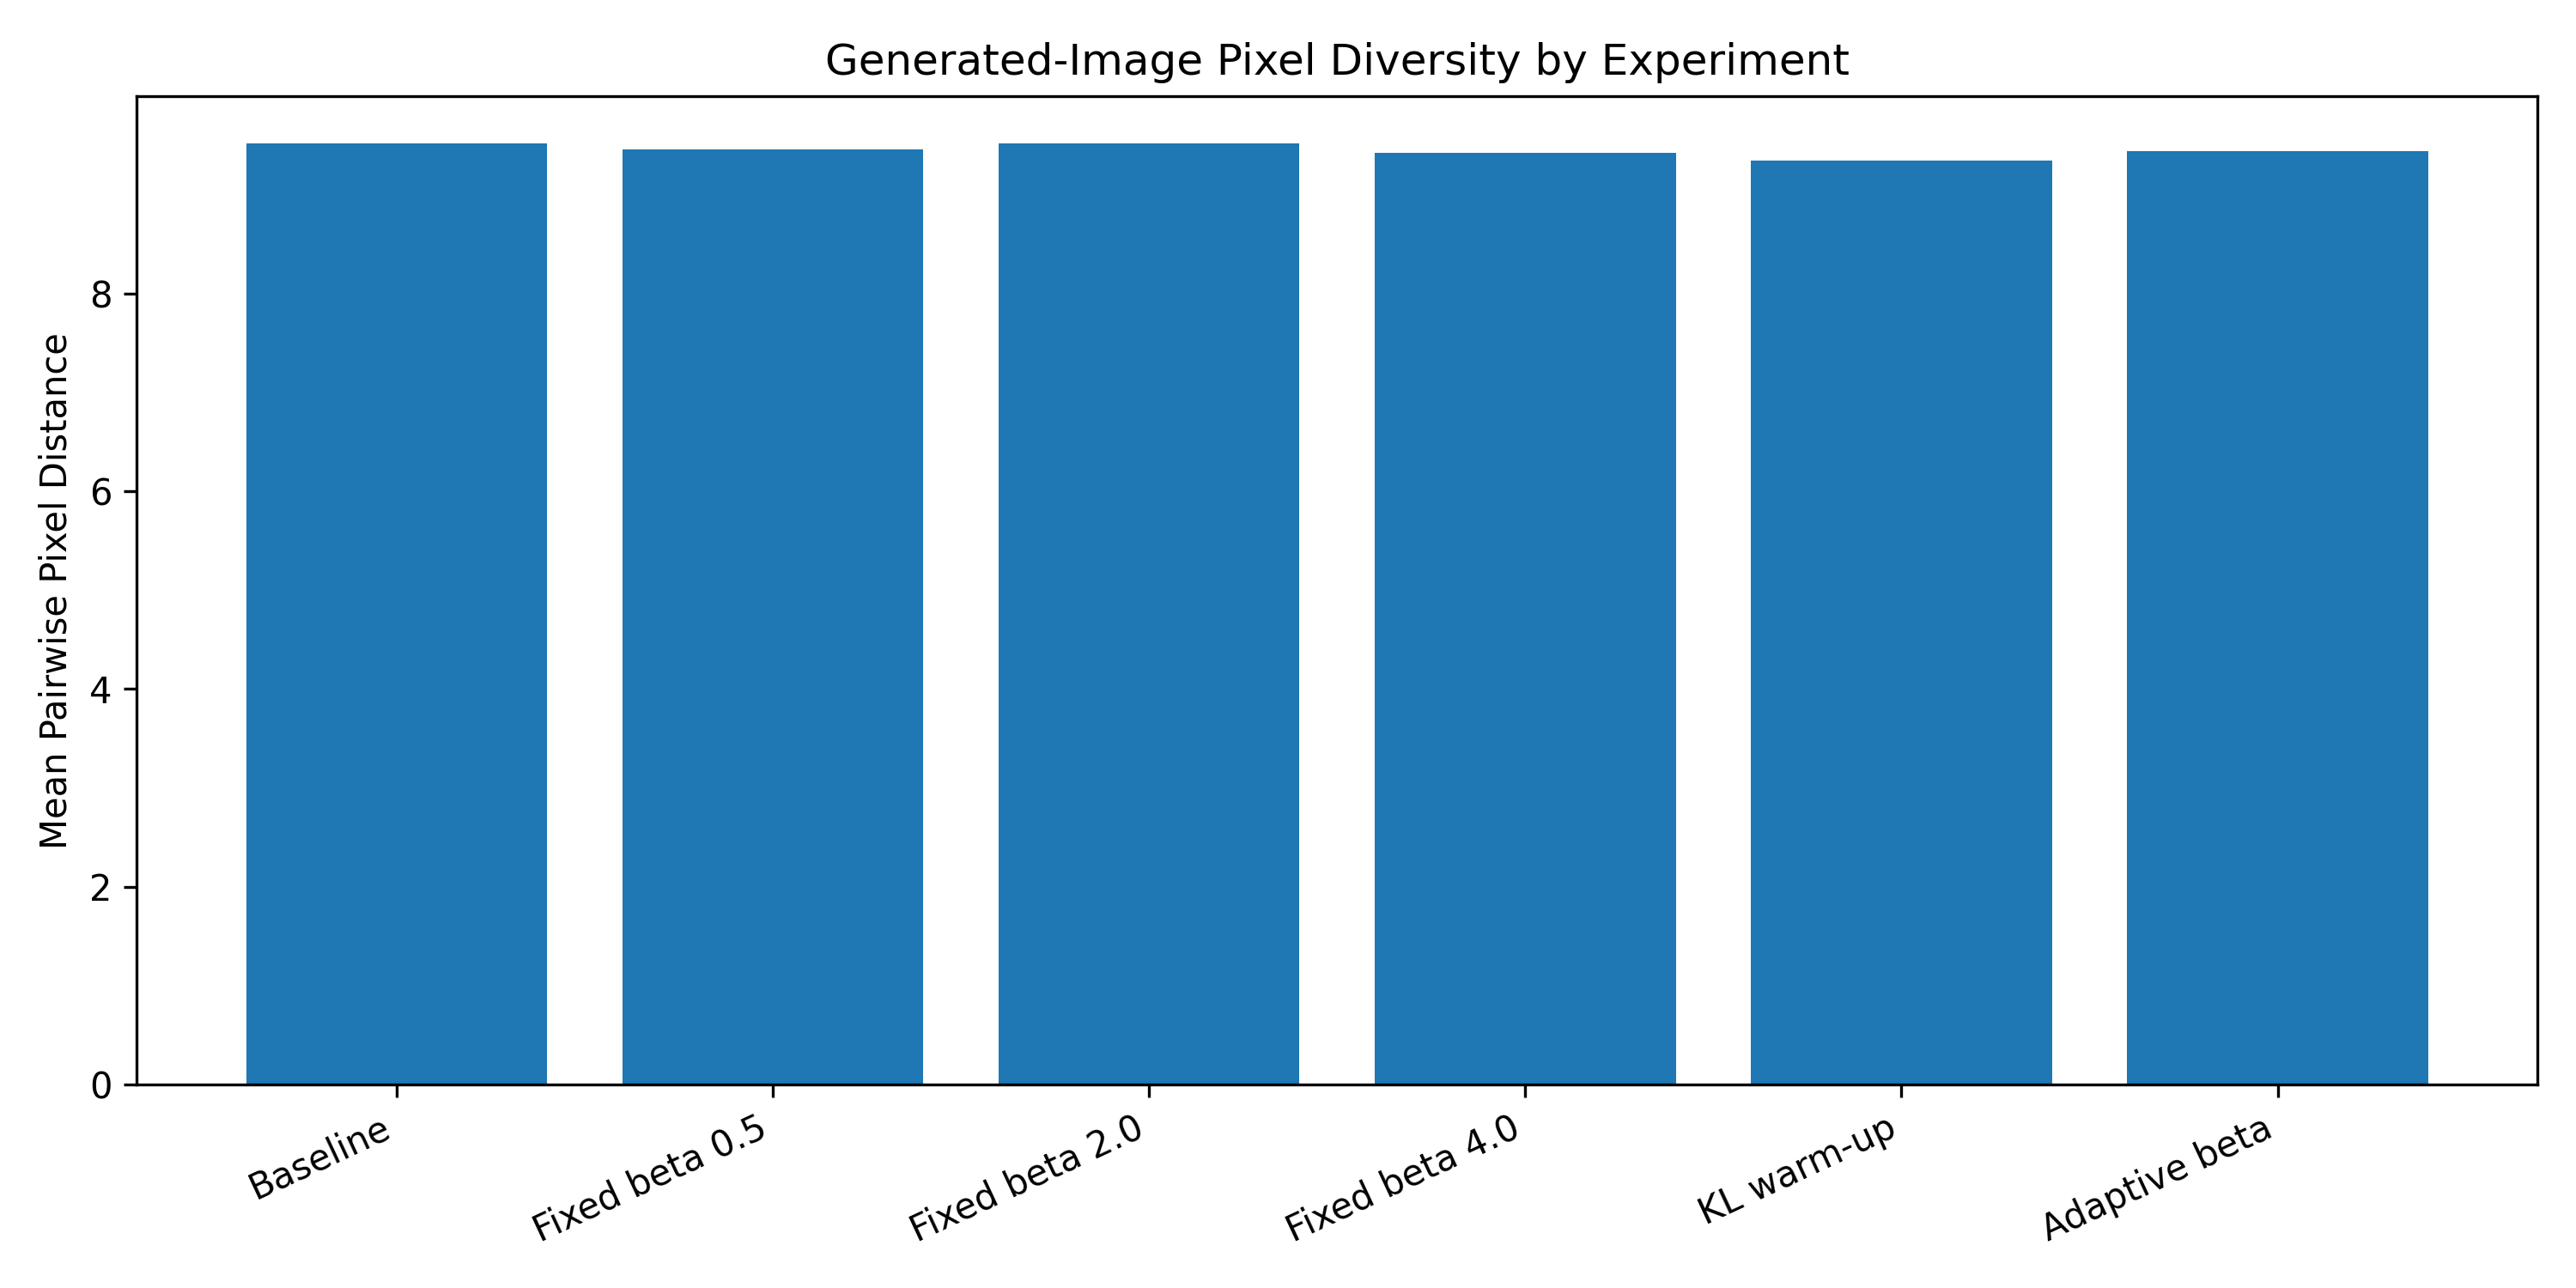

In [ ]:
from IPython.display import Image, display
import os

diversity_path = os.path.join(
    PROJECT_DIR,
    "figures",
    "diversity_comparison.png"
)

if os.path.exists(diversity_path):
    display(Image(filename=diversity_path))
else:
    print("Diversity comparison figure not found.")